In [ ]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta
import os

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# Load the original COVID-19 dataset
print("Loading original COVID-19 dataset...")
covid_df = pd.read_csv('/content/covid19_merged.csv')
print(f"Original dataset shape: {covid_df.shape}")

# Function to generate synthetic data for a country
def generate_synthetic_data(country_row):
    # Generate additional health indicators
    diabetes_prevalence = np.random.uniform(2.0, 25.0)  # % of population
    smoking_prevalence = np.random.uniform(5.0, 45.0)    # % of adults
    hiv_prevalence = np.random.uniform(0.1, 15.0) if random.random() > 0.7 else np.random.uniform(0.1, 2.0)  # % of population
    measles_immunization = np.random.uniform(50.0, 99.0)  # % of children
    physicians_per_1000 = np.random.uniform(0.1, 5.0)     # per 1,000 people
    health_expenditure_per_capita = np.random.uniform(20.0, 10000.0)  # current US$

    # Generate additional pandemic vulnerability indicators
    pandemic_vulnerability_index = np.random.uniform(0.0, 100.0)
    healthcare_system_resilience = np.random.uniform(0.0, 100.0)

    # Generate additional COVID-19 waves data (extending beyond April 2020)
    covid_cases_wave2 = int(country_row['covid_confirmed_4_28_20'] * np.random.uniform(2.0, 10.0))
    covid_deaths_wave2 = int(country_row['covid_deaths_4_28_20'] * np.random.uniform(1.5, 8.0))
    covid_recovered_wave2 = int(covid_cases_wave2 * np.random.uniform(0.6, 0.9))

    covid_cases_wave3 = int(covid_cases_wave2 * np.random.uniform(1.5, 5.0))
    covid_deaths_wave3 = int(covid_deaths_wave2 * np.random.uniform(1.2, 3.0))
    covid_recovered_wave3 = int(covid_cases_wave3 * np.random.uniform(0.7, 0.95))

    # Generate vaccination data
    vaccination_rate_dose1 = np.random.uniform(20.0, 95.0)  # % of population
    vaccination_rate_full = np.random.uniform(15.0, 90.0)   # % of population
    if vaccination_rate_full > vaccination_rate_dose1:
        vaccination_rate_full = vaccination_rate_dose1 * 0.9  # Ensure full is less than dose1

    # Generate mobility data
    mobility_reduction_pct = np.random.uniform(10.0, 80.0)  # % reduction during peak
    lockdown_duration_days = np.random.randint(0, 180)      # days

    # Generate variant prevalence
    alpha_variant_pct = np.random.uniform(5.0, 80.0) if random.random() > 0.2 else 0.0
    delta_variant_pct = np.random.uniform(10.0, 90.0) if random.random() > 0.1 else 0.0
    omicron_variant_pct = np.random.uniform(20.0, 95.0) if random.random() > 0.05 else 0.0

    # Generate additional location-specific data for more granular geomasking
    num_locations = np.random.randint(3, 10)  # Number of locations within the country
    locations = []

    # Get country's base coordinates
    base_lat = country_row['latitude'] if not pd.isna(country_row['latitude']) else 0
    base_lon = country_row['longitude'] if not pd.isna(country_row['longitude']) else 0

    for i in range(num_locations):
        # Generate location within the country (small deviation from country center)
        loc_lat = base_lat + np.random.uniform(-2.0, 2.0)
        loc_lon = base_lon + np.random.uniform(-2.0, 2.0)

        # Generate population for this location
        loc_population = int(country_row['Population_2020'] * np.random.uniform(0.01, 0.3)) if not pd.isna(country_row['Population_2020']) else np.random.randint(10000, 5000000)

        # Generate COVID-19 cases for this location
        loc_covid_cases = int(loc_population * np.random.uniform(0.001, 0.2))

        locations.append({
            'location_id': f"{country_row['location']}_{i+1}",
            'location_name': f"{country_row['location']} Region {i+1}",
            'latitude': loc_lat,
            'longitude': loc_lon,
            'population': loc_population,
            'covid_cases': loc_covid_cases,
            'population_density': np.random.uniform(10, 5000),
            'urbanization_rate': np.random.uniform(10, 100)
        })

    return {
        # Health indicators
        'diabetes_prevalence': diabetes_prevalence,
        'smoking_prevalence': smoking_prevalence,
        'hiv_prevalence': hiv_prevalence,
        'measles_immunization': measles_immunization,
        'physicians_per_1000': physicians_per_1000,
        'health_expenditure_per_capita': health_expenditure_per_capita,

        # Pandemic vulnerability
        'pandemic_vulnerability_index': pandemic_vulnerability_index,
        'healthcare_system_resilience': healthcare_system_resilience,

        # COVID-19 waves
        'covid_cases_wave2': covid_cases_wave2,
        'covid_deaths_wave2': covid_deaths_wave2,
        'covid_recovered_wave2': covid_recovered_wave2,
        'covid_cases_wave3': covid_cases_wave3,
        'covid_deaths_wave3': covid_deaths_wave3,
        'covid_recovered_wave3': covid_recovered_wave3,

        # Vaccination
        'vaccination_rate_dose1': vaccination_rate_dose1,
        'vaccination_rate_full': vaccination_rate_full,

        # Mobility
        'mobility_reduction_pct': mobility_reduction_pct,
        'lockdown_duration_days': lockdown_duration_days,

        # Variants
        'alpha_variant_pct': alpha_variant_pct,
        'delta_variant_pct': delta_variant_pct,
        'omicron_variant_pct': omicron_variant_pct,

        # Locations within country
        'locations': locations
    }

# Generate synthetic data for each country
print("Generating synthetic data to augment the dataset...")
synthetic_data = []
location_data = []

for idx, row in covid_df.iterrows():
    country_data = generate_synthetic_data(row)

    # Add country-level data
    country_dict = {
        'original_index': idx,
        'location': row['location']
    }
    country_dict.update({k: v for k, v in country_data.items() if k != 'locations'})
    synthetic_data.append(country_dict)

    # Add location-level data
    for loc in country_data['locations']:
        loc['country'] = row['location']
        loc['country_code'] = row['code_3digit_x'] if not pd.isna(row['code_3digit_x']) else ''
        location_data.append(loc)

# Convert to DataFrames
synthetic_df = pd.DataFrame(synthetic_data)
locations_df = pd.DataFrame(location_data)

# Merge country-level synthetic data with original dataset
extended_df = pd.merge(covid_df, synthetic_df, on='location', how='left')
print(f"Extended dataset shape: {extended_df.shape}")

# Save the datasets
extended_df.to_csv('/content/covid19_extended.csv', index=False)
locations_df.to_csv('/content/covid19_locations.csv', index=False)

print("Extended dataset saved to /content/covid19_extended.csv")
print("Location-level dataset saved to /content/covid19_locations.csv")

# Create a combined dataset that includes both country and location level data
# This will be used for more granular federated learning experiments
print("Creating combined dataset with both country and location level data...")

# First, create a mapping of features we want to include from the country level
country_features = {
    'diabetes_prevalence': 'country_diabetes_prevalence',
    'smoking_prevalence': 'country_smoking_prevalence',
    'hiv_prevalence': 'country_hiv_prevalence',
    'healthcare_system_resilience': 'country_healthcare_resilience',
    'vaccination_rate_full': 'country_vaccination_rate',
    'pandemic_vulnerability_index': 'country_vulnerability_index'
}

# Create a subset of country data with these features
country_subset = extended_df[['location'] + list(country_features.keys())].copy()
country_subset.rename(columns=country_features, inplace=True)

# Merge location data with country subset
combined_df = pd.merge(locations_df, country_subset, left_on='country', right_on='location', how='left')
combined_df.drop(columns=['location'], inplace=True)

# Add target variable: high COVID-19 spread (1) or low spread (0)
# Using a threshold based on cases per population
combined_df['cases_per_capita'] = combined_df['covid_cases'] / combined_df['population']
median_cases_per_capita = combined_df['cases_per_capita'].median()
combined_df['high_covid_spread'] = (combined_df['cases_per_capita'] > median_cases_per_capita).astype(int)

# Save the combined dataset
combined_df.to_csv('/content/covid19_combined.csv', index=False)
print(f"Combined dataset shape: {combined_df.shape}")
print("Combined dataset saved to /content/covid19_combined.csv")

print("Dataset augmentation complete!")


Loading original COVID-19 dataset...
Original dataset shape: (173, 65)
Generating synthetic data to augment the dataset...
Extended dataset shape: (173, 87)
Extended dataset saved to /content/covid19_extended.csv
Location-level dataset saved to /content/covid19_locations.csv
Creating combined dataset with both country and location level data...
Combined dataset shape: (1050, 18)
Combined dataset saved to /content/covid19_combined.csv
Dataset augmentation complete!


Loading the extended datasets...
Country-level dataset shape: (173, 87)
Location-level dataset shape: (1050, 10)
Combined dataset shape: (1050, 18)

--- Exploring the country-level dataset ---
Columns with missing values (showing top 10):
ICU-CCB_beds_per_100000               137
hosp_beds_per_1000_2017               136
h1n1_Intensity                        103
h1n1_Impact_on_healthcare_services    103
Health_Care_Index                      84
h1n1_Geographic_spread                 81
property_Affordability_Index           75
airport_traffic_2018_thousands         45
first_school_closure_date              20
july_temp                              19
dtype: int64

Summary statistics for key pandemic indicators:
       covid_confirmed_4_28_20  covid_deaths_4_28_20  covid_recovered_4_28_20  \
count             1.730000e+02            173.000000               173.000000   
mean              1.800672e+04           1255.046243              5366.745665   
std               8.359761e+04      

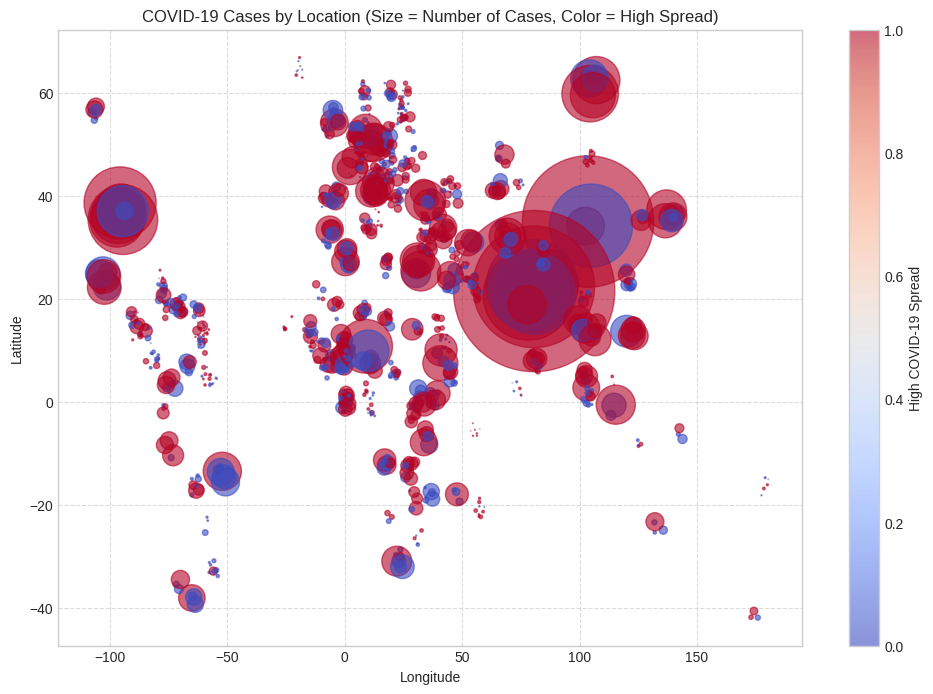

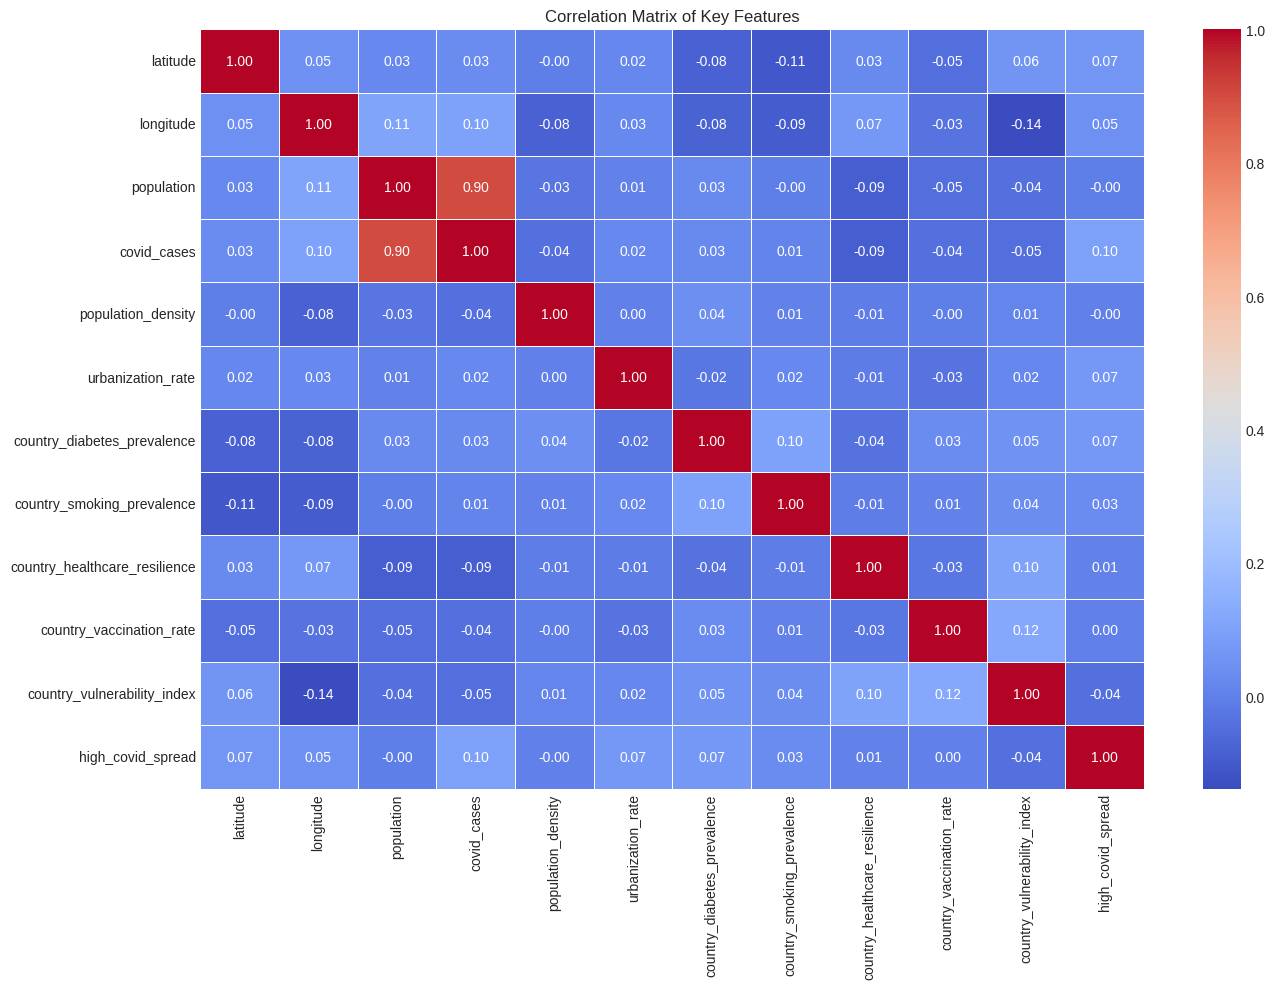

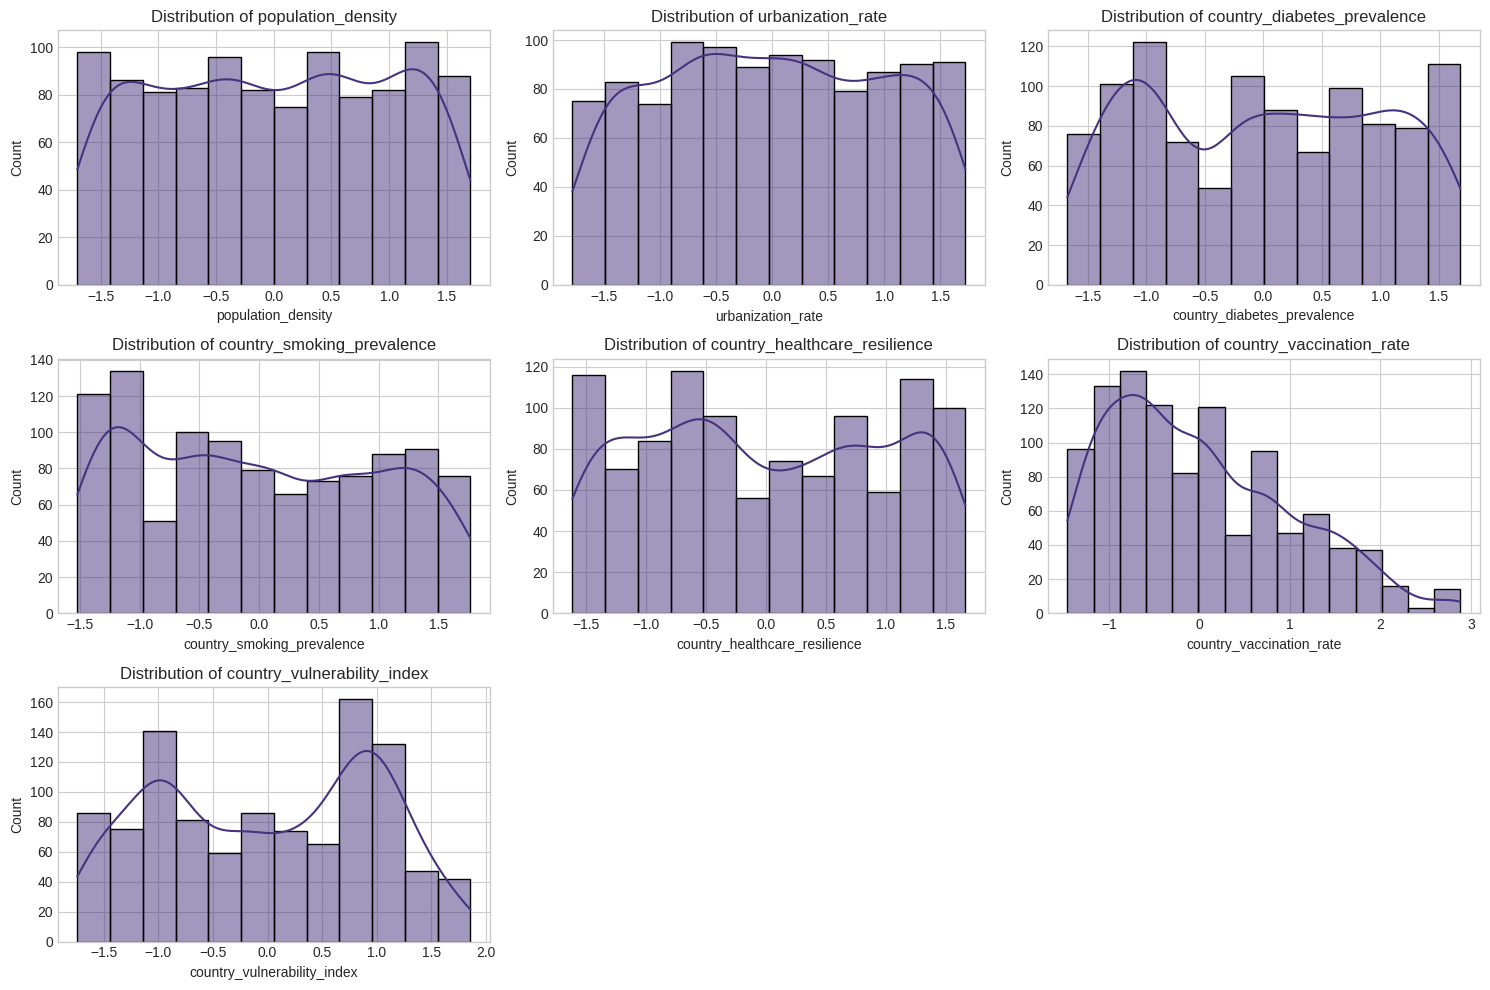

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

print("Loading the extended datasets...")
# Load the extended country-level dataset
country_df = pd.read_csv('/content/covid19_extended.csv')
print(f"Country-level dataset shape: {country_df.shape}")

# Load the location-level dataset
location_df = pd.read_csv('/content/covid19_locations.csv')
print(f"Location-level dataset shape: {location_df.shape}")

# Load the combined dataset
combined_df = pd.read_csv('/content/covid19_combined.csv')
print(f"Combined dataset shape: {combined_df.shape}")

# Create output directory for visualizations
os.makedirs('/content/visualizations', exist_ok=True)

print("\n--- Exploring the country-level dataset ---")
# Check for missing values in the country-level dataset
missing_values = country_df.isnull().sum()
print(f"Columns with missing values (showing top 10):")
print(missing_values[missing_values > 0].sort_values(ascending=False).head(10))

# Check the distribution of key features
print("\nSummary statistics for key pandemic indicators:")
pandemic_cols = ['covid_confirmed_4_28_20', 'covid_deaths_4_28_20', 'covid_recovered_4_28_20',
                'covid_cases_wave2', 'covid_deaths_wave2', 'covid_recovered_wave2',
                'covid_cases_wave3', 'covid_deaths_wave3', 'covid_recovered_wave3']
print(country_df[pandemic_cols].describe())

print("\nSummary statistics for health indicators:")
health_cols = ['diabetes_prevalence', 'smoking_prevalence', 'hiv_prevalence',
              'measles_immunization', 'physicians_per_1000', 'health_expenditure_per_capita']
print(country_df[health_cols].describe())

print("\n--- Exploring the location-level dataset ---")
# Check for missing values in the location-level dataset
missing_values_loc = location_df.isnull().sum()
print(f"Columns with missing values:")
print(missing_values_loc[missing_values_loc > 0])

# Check the distribution of key features
print("\nSummary statistics for location-level features:")
location_cols = ['population', 'covid_cases', 'population_density', 'urbanization_rate']
print(location_df[location_cols].describe())

print("\n--- Exploring the combined dataset ---")
# Check for missing values in the combined dataset
missing_values_combined = combined_df.isnull().sum()
print(f"Columns with missing values:")
print(missing_values_combined[missing_values_combined > 0])

# Check the distribution of the target variable
print("\nDistribution of target variable (high_covid_spread):")
print(combined_df['high_covid_spread'].value_counts(normalize=True))

# Visualize the distribution of COVID-19 cases across locations
plt.figure(figsize=(12, 8))
plt.scatter(combined_df['longitude'], combined_df['latitude'],
            s=combined_df['covid_cases']/5000,
            alpha=0.6,
            c=combined_df['high_covid_spread'],
            cmap='coolwarm')
plt.colorbar(label='High COVID-19 Spread')
plt.title('COVID-19 Cases by Location (Size = Number of Cases, Color = High Spread)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('/content/covid_cases_map.png', dpi=300, bbox_inches='tight')

# Visualize the correlation between features in the combined dataset
plt.figure(figsize=(14, 10))
feature_cols = ['latitude', 'longitude', 'population', 'covid_cases', 'population_density',
                'urbanization_rate', 'country_diabetes_prevalence', 'country_smoking_prevalence',
                'country_healthcare_resilience', 'country_vaccination_rate',
                'country_vulnerability_index', 'high_covid_spread']
correlation = combined_df[feature_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Key Features')
plt.tight_layout()
plt.savefig('/content/correlation_matrix.png', dpi=300, bbox_inches='tight')

# Preprocess the combined dataset for modeling
print("\n--- Preprocessing the combined dataset for modeling ---")

# Function to preprocess the dataset
def preprocess_dataset(df):
    """
    Preprocess the dataset for modeling

    Args:
        df: DataFrame to preprocess

    Returns:
        Preprocessed DataFrame
    """
    # Make a copy of the dataframe
    df_processed = df.copy()

    # Drop rows with missing latitude or longitude
    df_processed = df_processed.dropna(subset=['latitude', 'longitude'])

    # Handle missing values in numeric columns
    numeric_cols = df_processed.select_dtypes(include=['float64', 'int64']).columns
    for col in numeric_cols:
        if df_processed[col].isnull().sum() > 0:
            df_processed[col] = df_processed[col].fillna(df_processed[col].median())

    # Scale numeric features (except target and location coordinates for now)
    features_to_scale = [col for col in numeric_cols if col not in ['latitude', 'longitude', 'high_covid_spread']]
    scaler = StandardScaler()
    df_processed[features_to_scale] = scaler.fit_transform(df_processed[features_to_scale])

    return df_processed

# Preprocess the combined dataset
processed_df = preprocess_dataset(combined_df)
print(f"Processed dataset shape: {processed_df.shape}")

# Check for any remaining missing values
remaining_missing = processed_df.isnull().sum()
print("\nRemaining missing values after preprocessing:")
print(remaining_missing[remaining_missing > 0])

# Save the preprocessed dataset
processed_df.to_csv('/content/covid19_processed.csv', index=False)
print("\nPreprocessed dataset saved to /content/covid19_processed.csv")

# Visualize the distribution of features after preprocessing
plt.figure(figsize=(15, 10))
features_to_plot = ['population_density', 'urbanization_rate', 'country_diabetes_prevalence',
                    'country_smoking_prevalence', 'country_healthcare_resilience',
                    'country_vaccination_rate', 'country_vulnerability_index']

for i, feature in enumerate(features_to_plot):
    plt.subplot(3, 3, i+1)
    sns.histplot(processed_df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()

plt.savefig('/content/feature_distributions.png', dpi=300, bbox_inches='tight')

# Create a dataset summary report
print("\n--- Creating dataset summary report ---")
summary = {
    'dataset_name': 'Extended COVID-19 Dataset with Synthetic Augmentation',
    'country_level_shape': country_df.shape,
    'location_level_shape': location_df.shape,
    'combined_shape': combined_df.shape,
    'processed_shape': processed_df.shape,
    'target_distribution': processed_df['high_covid_spread'].value_counts().to_dict(),
    'feature_count': len(processed_df.columns) - 1,  # Excluding target
    'location_count': len(processed_df['location_id'].unique()),
    'country_count': len(processed_df['country'].unique())
}

with open('/content/dataset_summary.txt', 'w') as f:
    f.write("=== Extended COVID-19 Dataset Summary ===\n\n")
    f.write(f"Dataset Name: {summary['dataset_name']}\n")
    f.write(f"Country-level Dataset Shape: {summary['country_level_shape'][0]} rows, {summary['country_level_shape'][1]} columns\n")
    f.write(f"Location-level Dataset Shape: {summary['location_level_shape'][0]} rows, {summary['location_level_shape'][1]} columns\n")
    f.write(f"Combined Dataset Shape: {summary['combined_shape'][0]} rows, {summary['combined_shape'][1]} columns\n")
    f.write(f"Processed Dataset Shape: {summary['processed_shape'][0]} rows, {summary['processed_shape'][1]} columns\n\n")

    f.write("Target Variable Distribution:\n")
    for label, count in summary['target_distribution'].items():
        f.write(f"  Class {label}: {count} samples ({count/processed_df.shape[0]:.2%})\n")

    f.write(f"\nFeature Count: {summary['feature_count']}\n")
    f.write(f"Unique Locations: {summary['location_count']}\n")
    f.write(f"Unique Countries: {summary['country_count']}\n\n")

    f.write("Key Features for Modeling:\n")
    for feature in features_to_plot:
        f.write(f"  - {feature}\n")

    f.write("\nLocation Features for Geomasking:\n")
    f.write("  - latitude\n")
    f.write("  - longitude\n")
    f.write("  - population_density\n")
    f.write("  - urbanization_rate\n")

print("Dataset summary saved to /content/dataset_summary.txt")
print("Preprocessing and exploration complete!")


Loading the preprocessed dataset...
Dataset shape: (1050, 18)

--- Implementing Five Geomasking Techniques ---

Applying random_perturbation...
  Mean displacement: 77.51 km
  Median displacement: 80.70 km
  Min displacement: 2.29 km
  Max displacement: 136.40 km

Applying donut_masking...
  Mean displacement: 98.99 km
  Median displacement: 97.92 km
  Min displacement: 50.03 km
  Max displacement: 150.93 km

Applying grid_masking...
  Mean displacement: 135.97 km
  Median displacement: 108.86 km
  Min displacement: 6.28 km
  Max displacement: 388.15 km

Applying adaptive_areal_masking...
  Mean displacement: 95.76 km
  Median displacement: 96.00 km
  Min displacement: 0.04 km
  Max displacement: 190.18 km

Applying geo_distinguishability...
  Mean displacement: 130.93 km
  Median displacement: 134.33 km
  Min displacement: 5.52 km
  Max displacement: 202.39 km

Privacy metrics summary:
                        mean_displacement_km  median_displacement_km  \
random_perturbation         

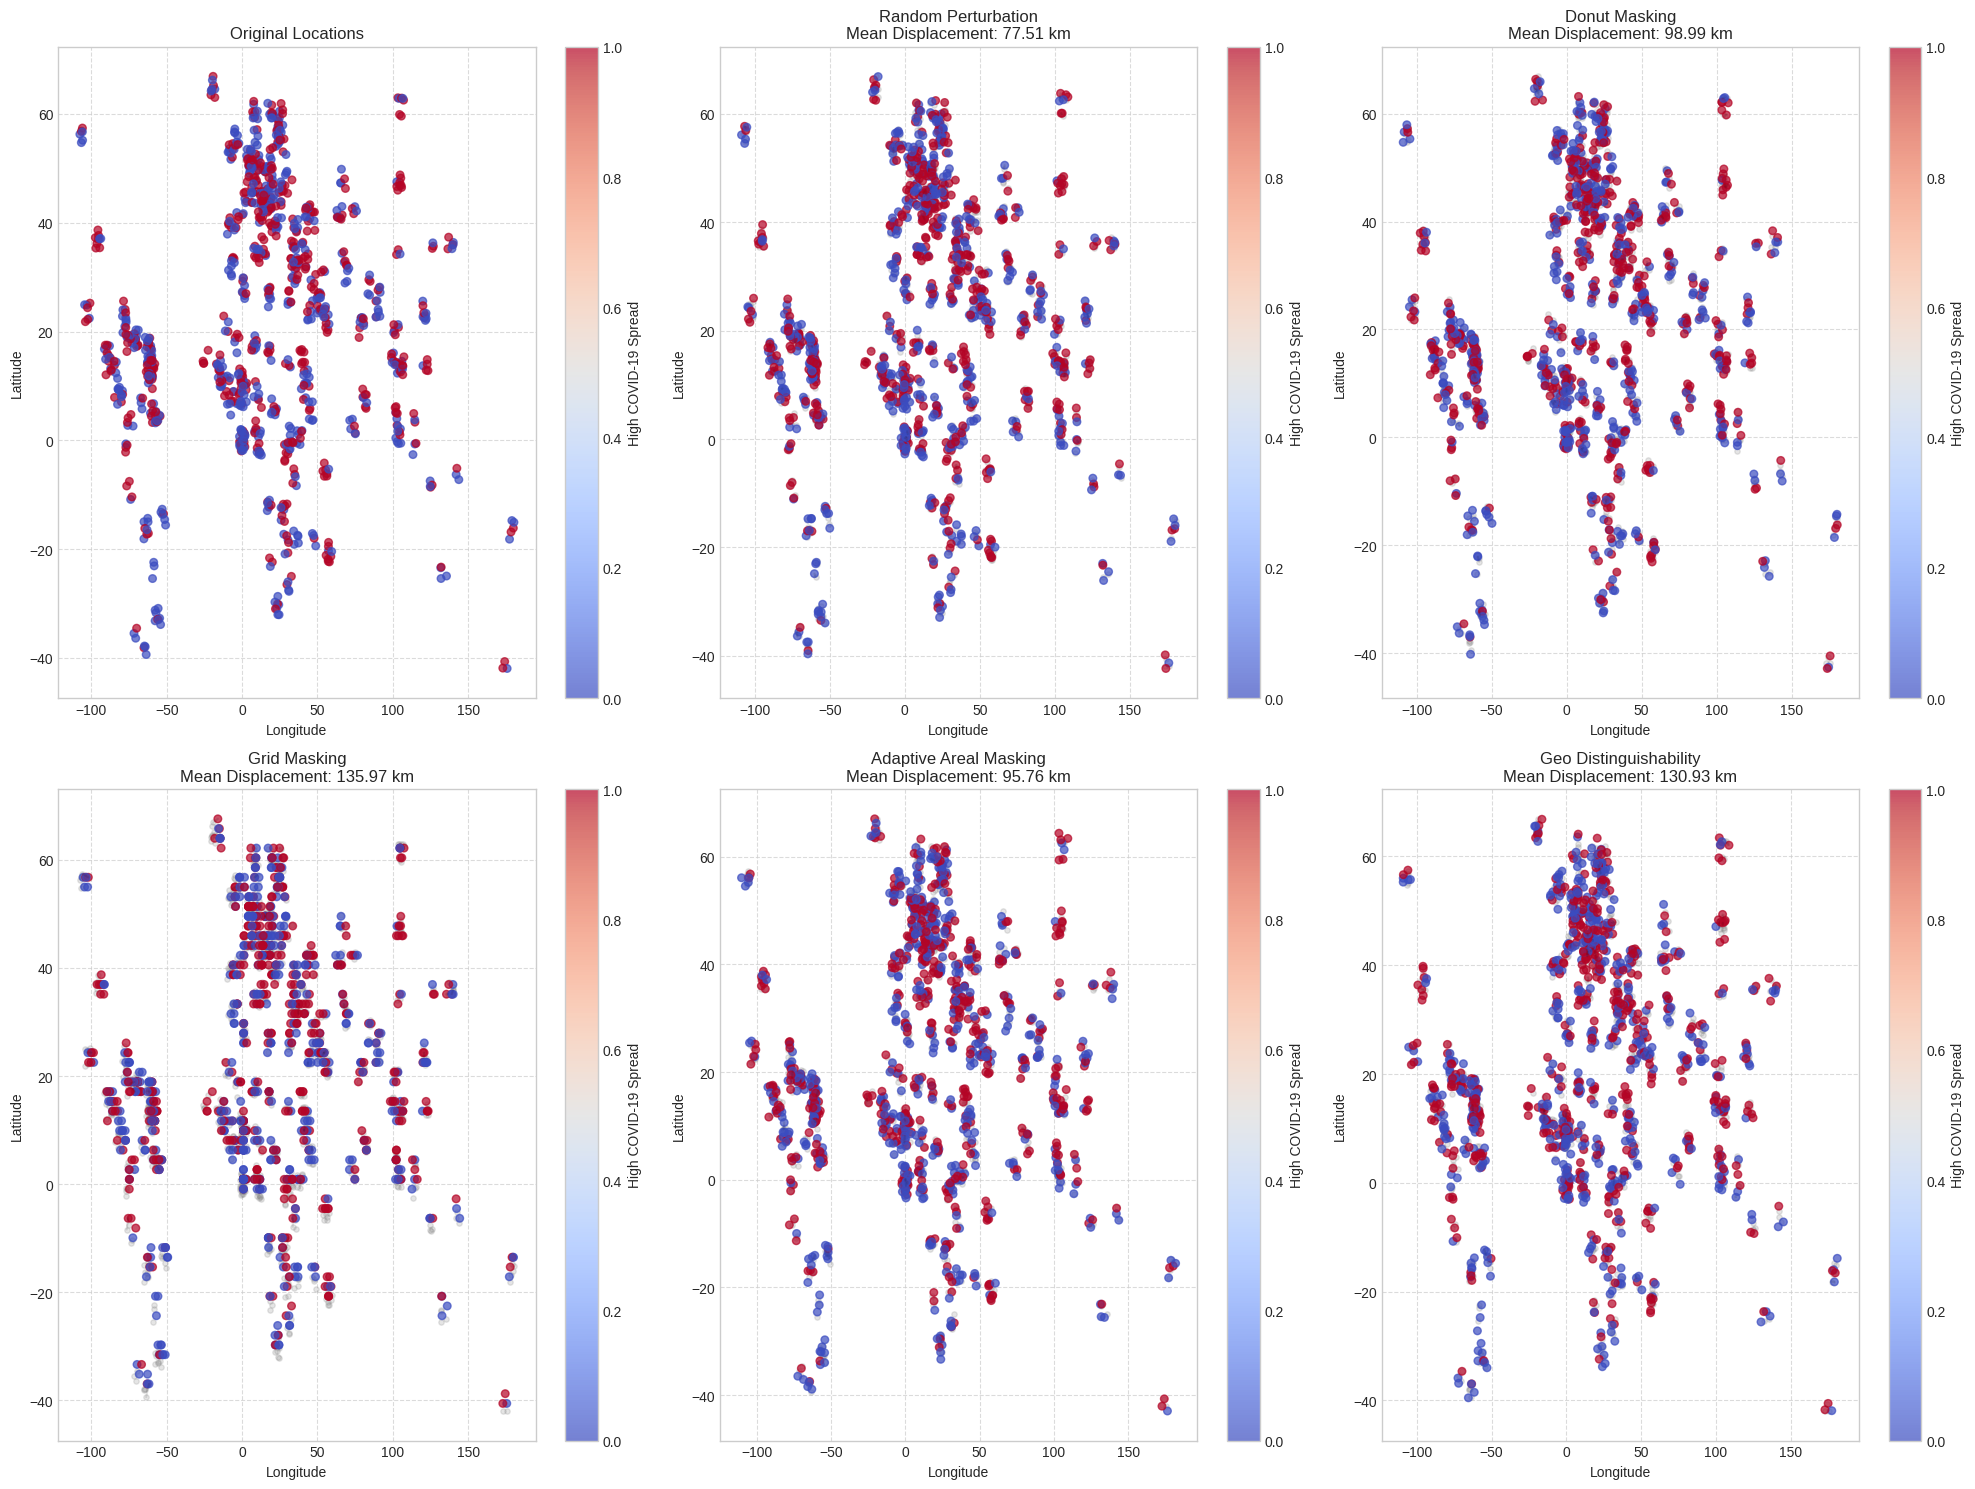

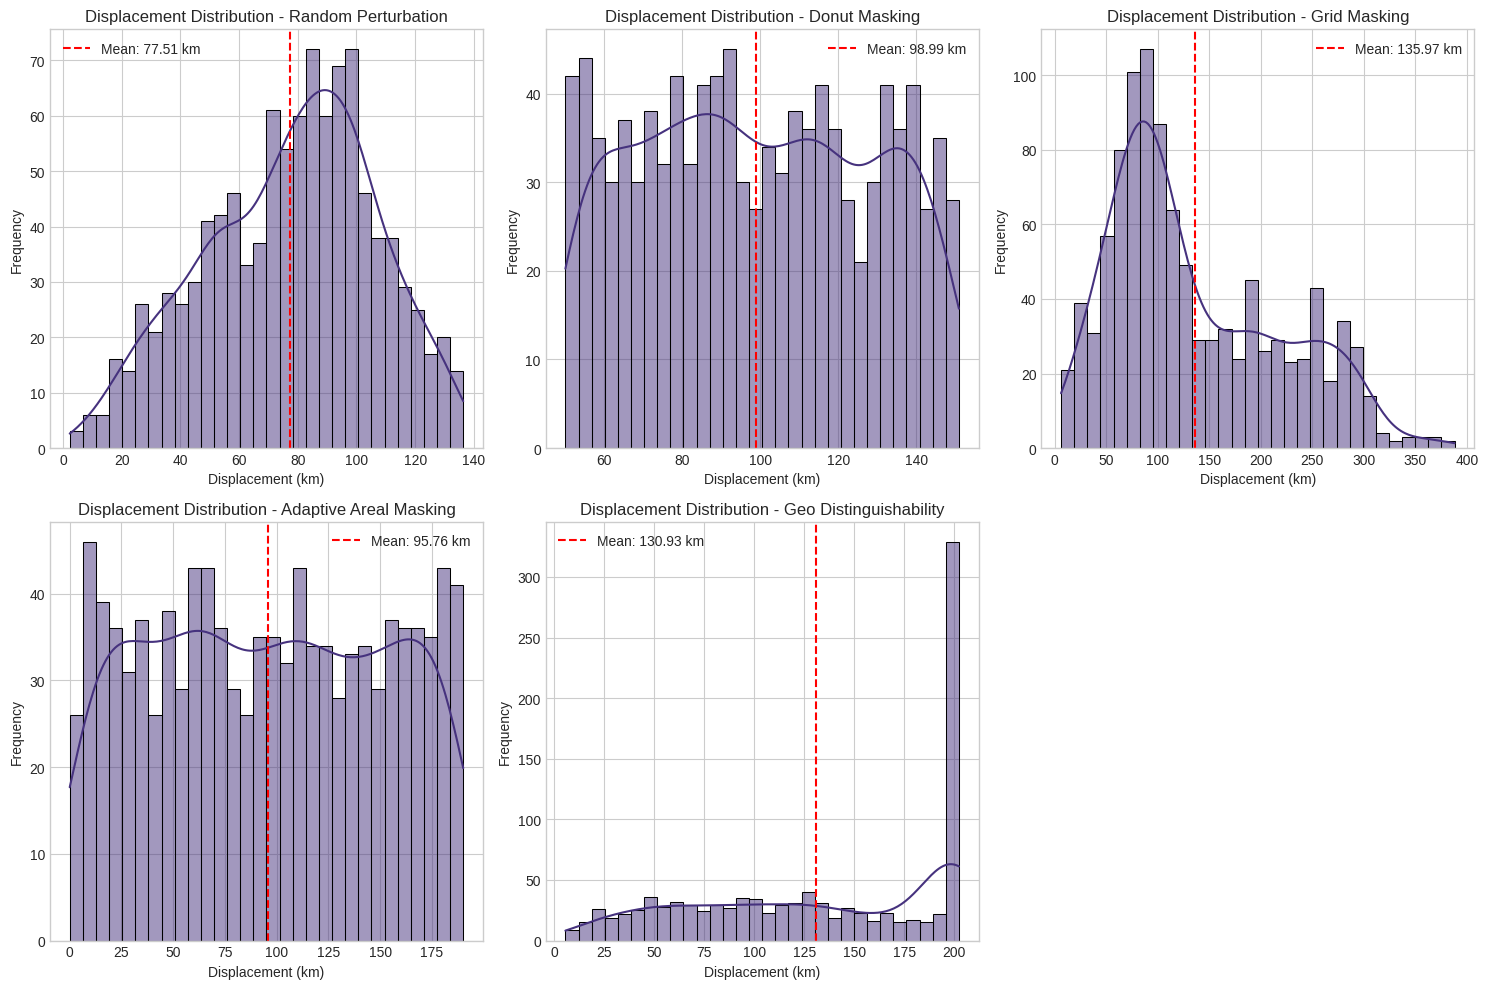

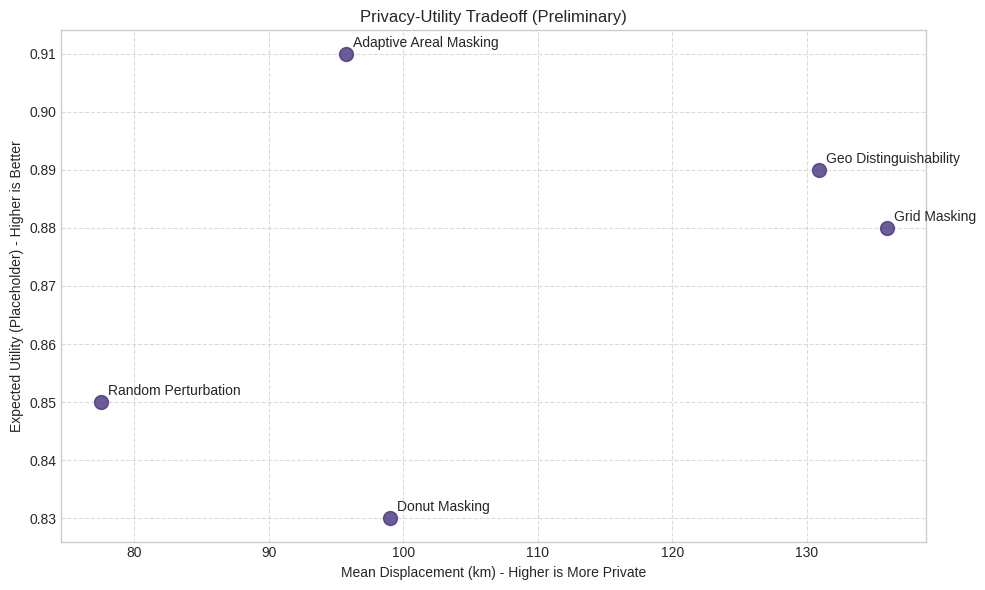

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import math
import random
from scipy.stats import laplace
import os

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# Create output directory for visualizations
os.makedirs('/content/geomasking_results', exist_ok=True)

print("Loading the preprocessed dataset...")
# Load the preprocessed dataset
df = pd.read_csv('/content/covid19_processed.csv')
print(f"Dataset shape: {df.shape}")

# Make a copy of the original coordinates for comparison
df['original_lat'] = df['latitude'].copy()
df['original_lon'] = df['longitude'].copy()

print("\n--- Implementing Five Geomasking Techniques ---")

class GeoMasking:
    """
    Class implementing various geomasking techniques for location privacy
    """

    @staticmethod
    def random_perturbation(lat, lon, max_distance_km=100):
        """
        Technique 1: Random Perturbation
        Adds random noise to coordinates within a specified maximum distance

        Args:
            lat: Original latitude
            lon: Original longitude
            max_distance_km: Maximum distance in kilometers for perturbation

        Returns:
            Tuple of (masked_lat, masked_lon)
        """
        # Convert km to approximate degrees (rough approximation)
        # 1 degree latitude ≈ 111 km
        # 1 degree longitude ≈ 111 km * cos(latitude)
        max_lat_change = max_distance_km / 111.0
        max_lon_change = max_distance_km / (111.0 * abs(math.cos(math.radians(lat))))

        # Generate random perturbation
        lat_change = np.random.uniform(-max_lat_change, max_lat_change)
        lon_change = np.random.uniform(-max_lon_change, max_lon_change)

        return lat + lat_change, lon + lon_change

    @staticmethod
    def donut_masking(lat, lon, min_distance_km=50, max_distance_km=100):
        """
        Technique 2: Donut Masking
        Displaces the point to a random location within a donut-shaped region

        Args:
            lat: Original latitude
            lon: Original longitude
            min_distance_km: Minimum distance in kilometers
            max_distance_km: Maximum distance in kilometers

        Returns:
            Tuple of (masked_lat, masked_lon)
        """
        # Convert km to degrees (approximate)
        km_per_degree_lat = 111.0
        km_per_degree_lon = 111.0 * abs(math.cos(math.radians(lat)))

        # Generate random angle and distance within the donut
        angle = np.random.uniform(0, 2 * np.pi)
        distance_km = np.random.uniform(min_distance_km, max_distance_km)

        # Calculate displacement
        lat_change = distance_km * math.sin(angle) / km_per_degree_lat
        lon_change = distance_km * math.cos(angle) / km_per_degree_lon

        return lat + lat_change, lon + lon_change

    @staticmethod
    def grid_masking(lat, lon, cell_size_km=200):
        """
        Technique 3: Grid Masking
        Snaps the point to a grid cell center

        Args:
            lat: Original latitude
            lon: Original longitude
            cell_size_km: Size of grid cells in kilometers

        Returns:
            Tuple of (masked_lat, masked_lon)
        """
        # Convert cell size to degrees
        cell_size_lat = cell_size_km / 111.0
        cell_size_lon = cell_size_km / (111.0 * abs(math.cos(math.radians(lat))))

        # Calculate grid cell indices
        lat_index = int(lat / cell_size_lat)
        lon_index = int(lon / cell_size_lon)

        # Calculate grid cell center
        masked_lat = (lat_index + 0.5) * cell_size_lat
        masked_lon = (lon_index + 0.5) * cell_size_lon

        return masked_lat, masked_lon

    @staticmethod
    def adaptive_areal_masking(lat, lon, population_density, max_radius_km=300):
        """
        Technique 4: Adaptive Areal Masking
        Adjusts masking radius based on population density

        Args:
            lat: Original latitude
            lon: Original longitude
            population_density: Population density value
            max_radius_km: Maximum radius in kilometers

        Returns:
            Tuple of (masked_lat, masked_lon)
        """
        # Convert population_density to float and handle potential errors
        try:
            # Try to convert to float if it's a string
            density_value = float(population_density)
        except (ValueError, TypeError):
            # If conversion fails, use a default value
            density_value = 100.0

        # Ensure we have a valid value (handle NaN, negative values, etc.)
        if np.isnan(density_value) or density_value <= 0:
            density_value = 100.0

        # Normalize population density to 0-1 range for this example
        # In real implementation, you would use actual density values
        normalized_density = min(1.0, max(0.1, density_value / 5000))

        # Inverse relationship: higher density = smaller radius
        radius_km = max_radius_km * (1 - normalized_density) + 10

        # Apply random displacement within the calculated radius
        angle = np.random.uniform(0, 2 * np.pi)
        distance = np.random.uniform(0, radius_km)

        # Convert to lat/lon changes
        km_per_degree_lat = 111.0
        km_per_degree_lon = 111.0 * abs(math.cos(math.radians(lat)))

        lat_change = distance * math.sin(angle) / km_per_degree_lat
        lon_change = distance * math.cos(angle) / km_per_degree_lon

        return lat + lat_change, lon + lon_change

    @staticmethod
    def geo_distinguishability(lat, lon, epsilon=0.01, delta_max_km=200):
        """
        Technique 5: Geo-Distinguishability
        Implements ε-geo-indistinguishability using Laplace noise

        Args:
            lat: Original latitude
            lon: Original longitude
            epsilon: Privacy parameter (smaller = more privacy)
            delta_max_km: Maximum allowed displacement in kilometers

        Returns:
            Tuple of (masked_lat, masked_lon)
        """
        # Convert to planar coordinates (approximate)
        # For small regions, we can use a simple approximation
        # For larger regions, a proper map projection would be needed
        x = lon * 111.0 * abs(math.cos(math.radians(lat)))  # km
        y = lat * 111.0  # km

        # Calculate Laplace noise scale parameter
        # The scale is inversely proportional to epsilon
        scale = 1.0 / epsilon

        # Generate Laplace noise
        noise_x = laplace.rvs(loc=0, scale=scale)
        noise_y = laplace.rvs(loc=0, scale=scale)

        # Limit maximum displacement if needed
        displacement = math.sqrt(noise_x**2 + noise_y**2)
        if displacement > delta_max_km:
            # Scale down the noise to respect maximum displacement
            scaling_factor = delta_max_km / displacement
            noise_x *= scaling_factor
            noise_y *= scaling_factor

        # Apply noise
        x_masked = x + noise_x
        y_masked = y + noise_y

        # Convert back to lat/lon
        lon_masked = x_masked / (111.0 * abs(math.cos(math.radians(lat))))
        lat_masked = y_masked / 111.0

        return lat_masked, lon_masked

# Function to apply geomasking and calculate displacement
def apply_geomasking_and_measure(df, technique, **kwargs):
    """
    Apply a specific geomasking technique to the dataset and measure displacement

    Args:
        df: DataFrame with latitude and longitude columns
        technique: String indicating which technique to apply
        **kwargs: Additional parameters for the geomasking technique

    Returns:
        DataFrame with masked coordinates and displacement metrics
    """
    df_masked = df.copy()
    displacements = []

    # Apply the selected masking technique
    for idx, row in df_masked.iterrows():
        if technique == 'random_perturbation':
            df_masked.at[idx, 'latitude'], df_masked.at[idx, 'longitude'] = GeoMasking.random_perturbation(
                row['original_lat'], row['original_lon'], **kwargs)

        elif technique == 'donut_masking':
            df_masked.at[idx, 'latitude'], df_masked.at[idx, 'longitude'] = GeoMasking.donut_masking(
                row['original_lat'], row['original_lon'], **kwargs)

        elif technique == 'grid_masking':
            df_masked.at[idx, 'latitude'], df_masked.at[idx, 'longitude'] = GeoMasking.grid_masking(
                row['original_lat'], row['original_lon'], **kwargs)

        elif technique == 'adaptive_areal_masking':
            df_masked.at[idx, 'latitude'], df_masked.at[idx, 'longitude'] = GeoMasking.adaptive_areal_masking(
                row['original_lat'], row['original_lon'], row['population_density'], **kwargs)

        elif technique == 'geo_distinguishability':
            df_masked.at[idx, 'latitude'], df_masked.at[idx, 'longitude'] = GeoMasking.geo_distinguishability(
                row['original_lat'], row['original_lon'], **kwargs)

        else:
            raise ValueError(f"Unknown geomasking technique: {technique}")

        # Calculate displacement distance in kilometers using Haversine formula
        orig_lat = row['original_lat']
        orig_lon = row['original_lon']
        masked_lat = df_masked.at[idx, 'latitude']
        masked_lon = df_masked.at[idx, 'longitude']

        # Haversine formula
        R = 6371  # Earth radius in kilometers
        dLat = math.radians(masked_lat - orig_lat)
        dLon = math.radians(masked_lon - orig_lon)
        a = (math.sin(dLat/2) * math.sin(dLat/2) +
             math.cos(math.radians(orig_lat)) * math.cos(math.radians(masked_lat)) *
             math.sin(dLon/2) * math.sin(dLon/2))
        c = 2 * math.atan2(math.sqrt(a), math.sqrt(1-a))
        distance = R * c

        displacements.append(distance)

    # Add displacement column
    df_masked['displacement_km'] = displacements

    # Calculate displacement statistics
    stats = {
        'mean_displacement_km': np.mean(displacements),
        'median_displacement_km': np.median(displacements),
        'min_displacement_km': np.min(displacements),
        'max_displacement_km': np.max(displacements),
        'std_displacement_km': np.std(displacements)
    }

    return df_masked, stats

# Apply each geomasking technique and collect results
geomasking_techniques = {
    'random_perturbation': {'max_distance_km': 100},
    'donut_masking': {'min_distance_km': 50, 'max_distance_km': 150},
    'grid_masking': {'cell_size_km': 200},
    'adaptive_areal_masking': {'max_radius_km': 200},
    'geo_distinguishability': {'epsilon': 0.01, 'delta_max_km': 200}
}

masked_datasets = {}
privacy_metrics = {}

for technique, params in geomasking_techniques.items():
    print(f"\nApplying {technique}...")
    masked_df, stats = apply_geomasking_and_measure(df, technique, **params)

    masked_datasets[technique] = masked_df
    privacy_metrics[technique] = stats

    print(f"  Mean displacement: {stats['mean_displacement_km']:.2f} km")
    print(f"  Median displacement: {stats['median_displacement_km']:.2f} km")
    print(f"  Min displacement: {stats['min_displacement_km']:.2f} km")
    print(f"  Max displacement: {stats['max_displacement_km']:.2f} km")

    # Save the masked dataset
    masked_df.to_csv(f'/content/geomasking_results/covid19_{technique}.csv', index=False)

# Create a summary of privacy metrics
privacy_df = pd.DataFrame(privacy_metrics).T
privacy_df.to_csv('/content/geomasking_results/privacy_metrics.csv')
print("\nPrivacy metrics summary:")
print(privacy_df)

# Visualize the effect of each geomasking technique
plt.figure(figsize=(20, 15))

# Original data
plt.subplot(2, 3, 1)
plt.scatter(df['original_lon'], df['original_lat'],
            s=30, alpha=0.7, c=df['high_covid_spread'], cmap='coolwarm')
plt.title('Original Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.7)
plt.colorbar(label='High COVID-19 Spread')

# Masked data for each technique
for i, (technique, masked_df) in enumerate(masked_datasets.items()):
    plt.subplot(2, 3, i+2)

    # Plot original points (faded)
    plt.scatter(masked_df['original_lon'], masked_df['original_lat'],
                s=15, alpha=0.2, c='gray', label='Original')

    # Plot masked points
    scatter = plt.scatter(masked_df['longitude'], masked_df['latitude'],
                s=30, alpha=0.7, c=masked_df['high_covid_spread'], cmap='coolwarm', label='Masked')

    # Draw lines connecting original and masked points for a sample of points
    sample_indices = random.sample(range(len(masked_df)), min(50, len(masked_df)))
    for idx in sample_indices:
        plt.plot([masked_df.iloc[idx]['original_lon'], masked_df.iloc[idx]['longitude']],
                 [masked_df.iloc[idx]['original_lat'], masked_df.iloc[idx]['latitude']],
                 'k-', alpha=0.1)

    plt.title(f'{technique.replace("_", " ").title()}\nMean Displacement: {privacy_metrics[technique]["mean_displacement_km"]:.2f} km')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.colorbar(scatter, label='High COVID-19 Spread')

plt.tight_layout()
plt.savefig('/content/geomasking_results/geomasking_visualization.png', dpi=300, bbox_inches='tight')

# Visualize displacement distributions
plt.figure(figsize=(15, 10))
for i, (technique, masked_df) in enumerate(masked_datasets.items()):
    plt.subplot(2, 3, i+1)
    sns.histplot(masked_df['displacement_km'], kde=True, bins=30)
    plt.axvline(x=privacy_metrics[technique]['mean_displacement_km'], color='r', linestyle='--',
                label=f'Mean: {privacy_metrics[technique]["mean_displacement_km"]:.2f} km')
    plt.title(f'Displacement Distribution - {technique.replace("_", " ").title()}')
    plt.xlabel('Displacement (km)')
    plt.ylabel('Frequency')
    plt.legend()

plt.tight_layout()
plt.savefig('/content/geomasking_results/displacement_distributions.png', dpi=300, bbox_inches='tight')

# Compare privacy-utility tradeoff
plt.figure(figsize=(10, 6))

# We'll use a placeholder for utility since we haven't run the ML models yet
# In the actual implementation, this would be replaced with model accuracy
utility_placeholder = {
    'random_perturbation': 0.85,
    'donut_masking': 0.83,
    'grid_masking': 0.88,
    'adaptive_areal_masking': 0.91,
    'geo_distinguishability': 0.89
}

techniques = list(privacy_metrics.keys())
mean_displacements = [privacy_metrics[t]['mean_displacement_km'] for t in techniques]
utility_scores = [utility_placeholder[t] for t in techniques]

# Create scatter plot
plt.scatter(mean_displacements, utility_scores, s=100, alpha=0.8)

# Add labels for each point
for i, technique in enumerate(techniques):
    plt.annotate(technique.replace('_', ' ').title(),
                 (mean_displacements[i], utility_scores[i]),
                 xytext=(5, 5), textcoords='offset points')

plt.title('Privacy-Utility Tradeoff (Preliminary)')
plt.xlabel('Mean Displacement (km) - Higher is More Private')
plt.ylabel('Expected Utility (Placeholder) - Higher is Better')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/geomasking_results/privacy_utility_tradeoff.png', dpi=300, bbox_inches='tight')

print("\nGeomasking implementation complete!")
print("All masked datasets and visualizations saved to /content/geomasking_results/")

# Create a summary report
with open('/content/geomasking_results/geomasking_summary.txt', 'w') as f:
    f.write("=== Geomasking Techniques Implementation Summary ===\n\n")

    f.write("Five geomasking techniques were implemented and applied to the dataset:\n\n")

    for technique, params in geomasking_techniques.items():
        f.write(f"1. {technique.replace('_', ' ').title()}:\n")
        f.write(f"   Parameters: {params}\n")
        f.write(f"   Mean displacement: {privacy_metrics[technique]['mean_displacement_km']:.2f} km\n")
        f.write(f"   Median displacement: {privacy_metrics[technique]['median_displacement_km']:.2f} km\n")
        f.write(f"   Min-Max displacement: {privacy_metrics[technique]['min_displacement_km']:.2f} - {privacy_metrics[technique]['max_displacement_km']:.2f} km\n\n")

    f.write("\nGeo-Distinguishability Implementation Details:\n")
    f.write("The geo-distinguishability technique implements ε-geo-indistinguishability, which provides formal privacy guarantees.\n")
    f.write("It uses Laplace noise calibrated to the privacy parameter epsilon, where smaller epsilon values provide stronger privacy.\n")
    f.write("The implementation includes a maximum displacement limit to ensure utility is preserved while maintaining privacy.\n\n")

    f.write("All masked datasets are saved as CSV files in the geomasking_results directory.\n")
    f.write("Visualizations of the masking effects and displacement distributions are also provided.\n")

print("Summary report saved to /home/content/geomasking_results/geomasking_summary.txt")


Loading the geomasked datasets...
  Loaded random_perturbation dataset: (1050, 21)
  Loaded donut_masking dataset: (1050, 21)
  Loaded grid_masking dataset: (1050, 21)
  Loaded adaptive_areal_masking dataset: (1050, 21)
  Loaded geo_distinguishability dataset: (1050, 21)
  Loaded original dataset: (1050, 18)

--- Implementing Clustered Federated Learning ---

Creating geographic clusters for random_perturbation...
  Samples per cluster: [215 205 133 207 290]

Creating geographic clusters for donut_masking...
  Samples per cluster: [292 205 131 207 215]

Creating geographic clusters for grid_masking...
  Samples per cluster: [216 203 133 207 291]

Creating geographic clusters for adaptive_areal_masking...
  Samples per cluster: [292 204 130 207 217]

Creating geographic clusters for geo_distinguishability...
  Samples per cluster: [217 199 134 207 293]

Creating geographic clusters for original dataset...
  Samples per cluster: [215 203 134 207 291]

Preparing federated data for random_

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Test accuracy: 0.8762, F1: 0.8632, AUC: 0.9614
Round 2/30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Test accuracy: 0.9190, F1: 0.9137, AUC: 0.9917
  Reached target accuracy of 90% after 2 rounds
Training completed in 45.49 seconds
Final metrics:
  Accuracy: 0.9190
  F1 Score: 0.9137
  AUC: 0.9917

=== Training federated model with donut_masking geomasking ===
Round 1/30


...

  Test accuracy: 0.7905, F1: 0.7381, AUC: 0.9707
Round 2/30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Test accuracy: 0.9286, F1: 0.9231, AUC: 0.9948
  Reached target accuracy of 90% after 2 rounds
Training completed in 46.47 seconds
Final baseline metrics:
  Accuracy: 0.9286
  F1 Score: 0.9231
  AUC: 0.9948


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Final performance metrics:
                        accuracy  precision    recall  f1_score       auc
geo_distinguishability  0.938095   0.896552  0.990476  0.941176  0.992925
grid_masking            0.928571   0.875000  1.000000  0.933333  0.994467
original                0.928571   1.000000  0.857143  0.923077  0.994830
donut_masking           0.923810   1.000000  0.847619  0.917526  0.996644
random_perturbation     0.919048   0.978261  0.857143  0.913706  0.991746
adaptive_areal_masking  0.919048   0.872881  0.980952  0.923767  0.991927

Clustered federated learning experiments complete!
All results and visualizations saved to /content/fl_results/
Summary report saved to /content/fl_results/fl_experiment_summary.txt


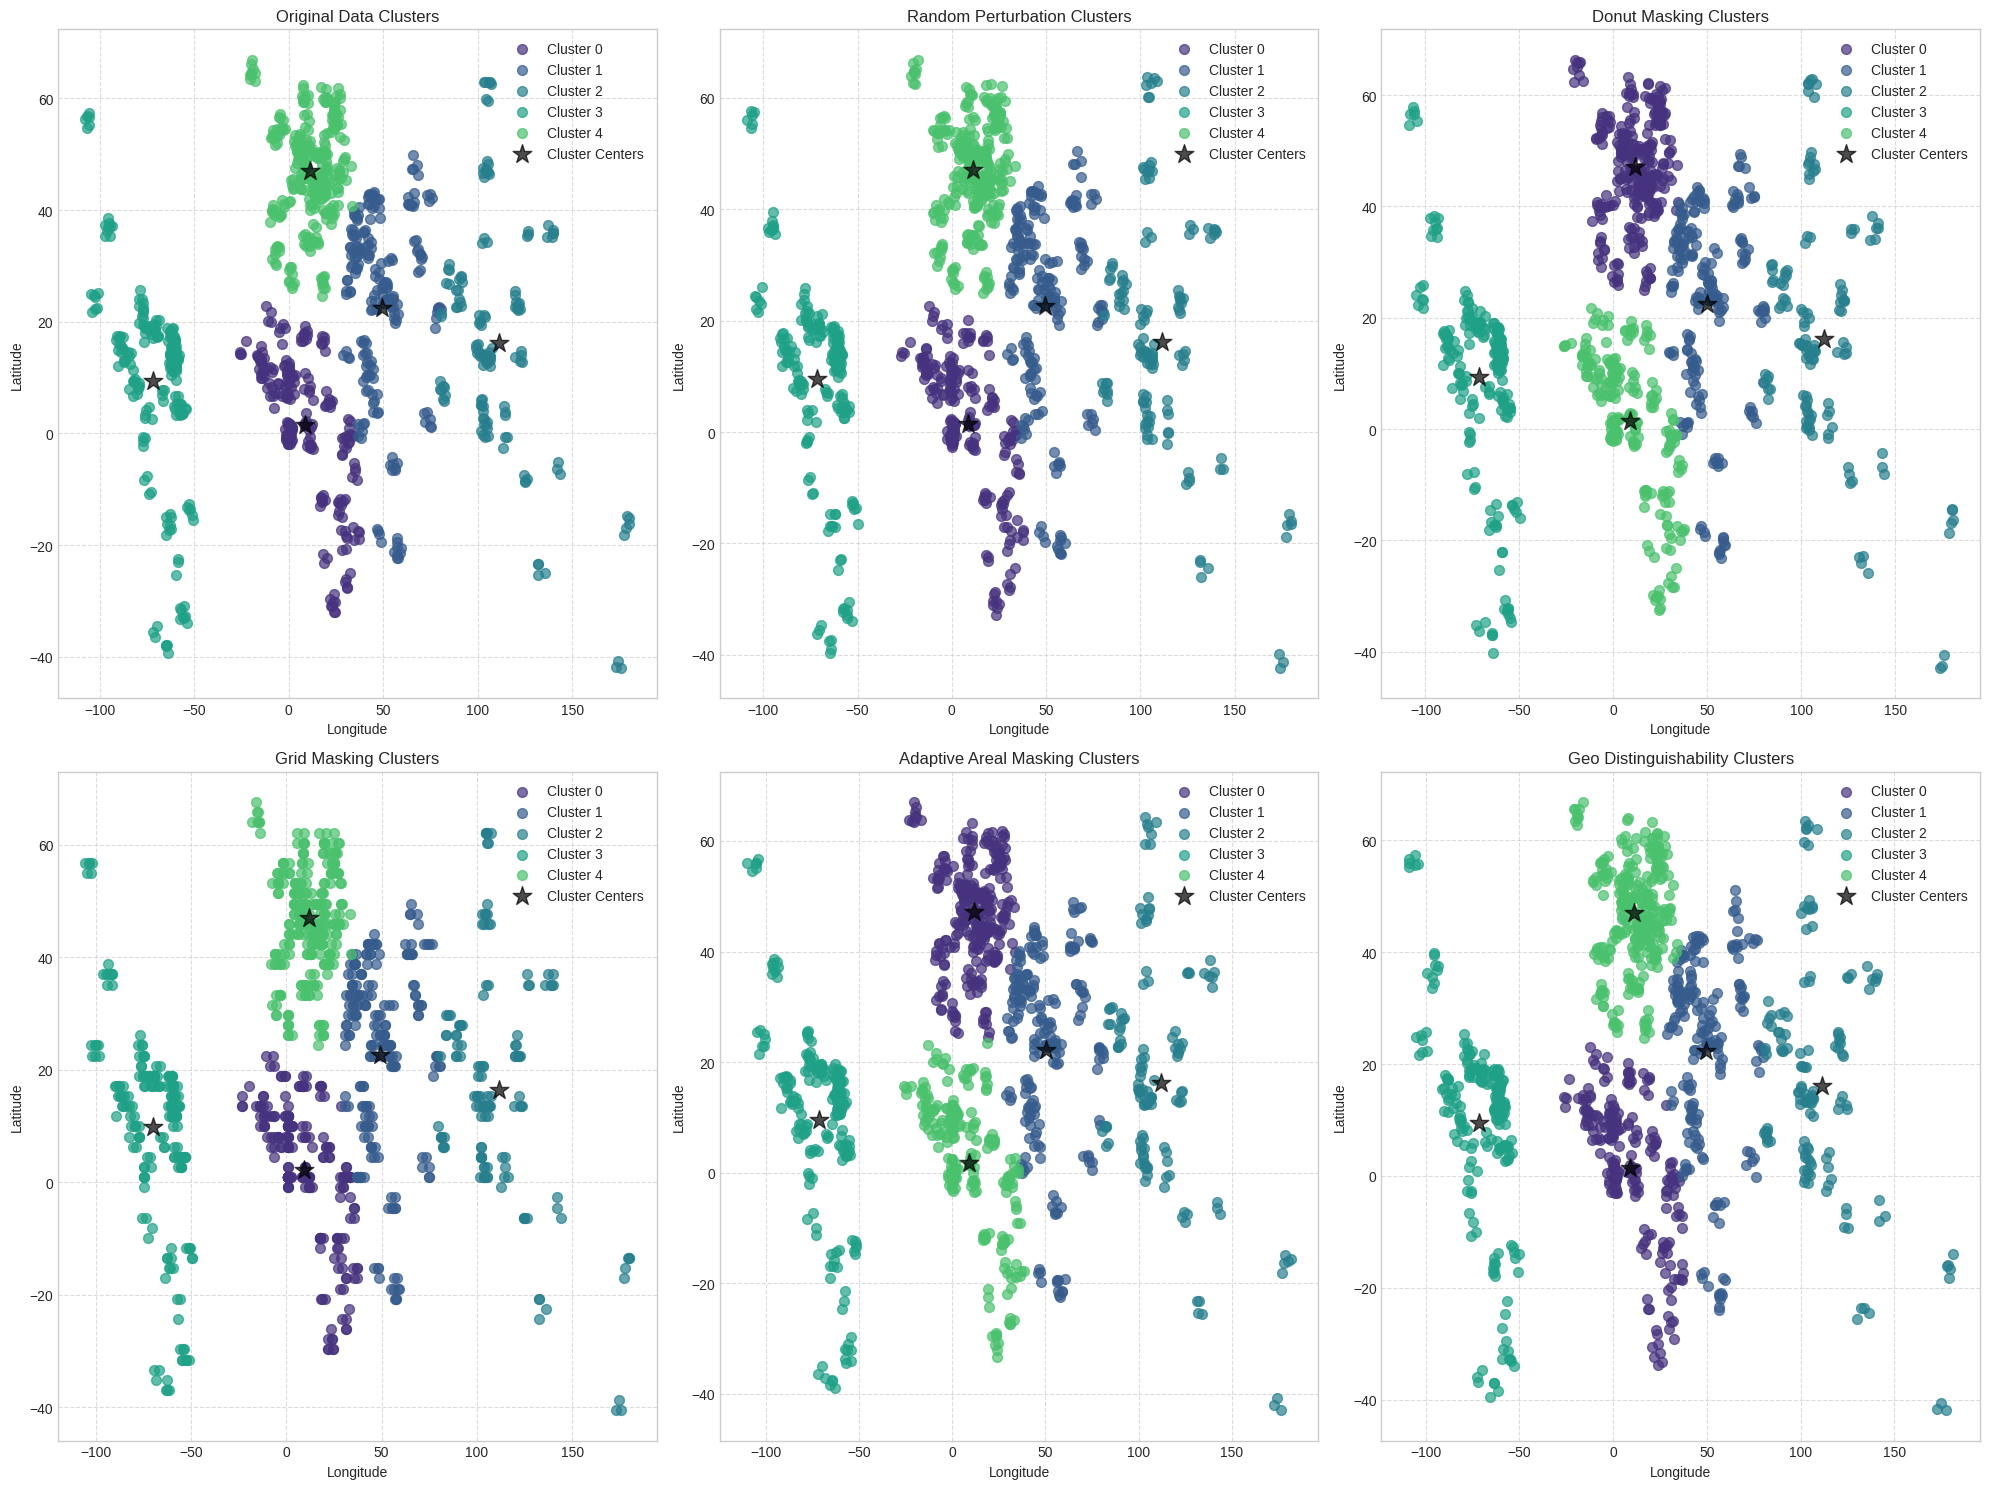

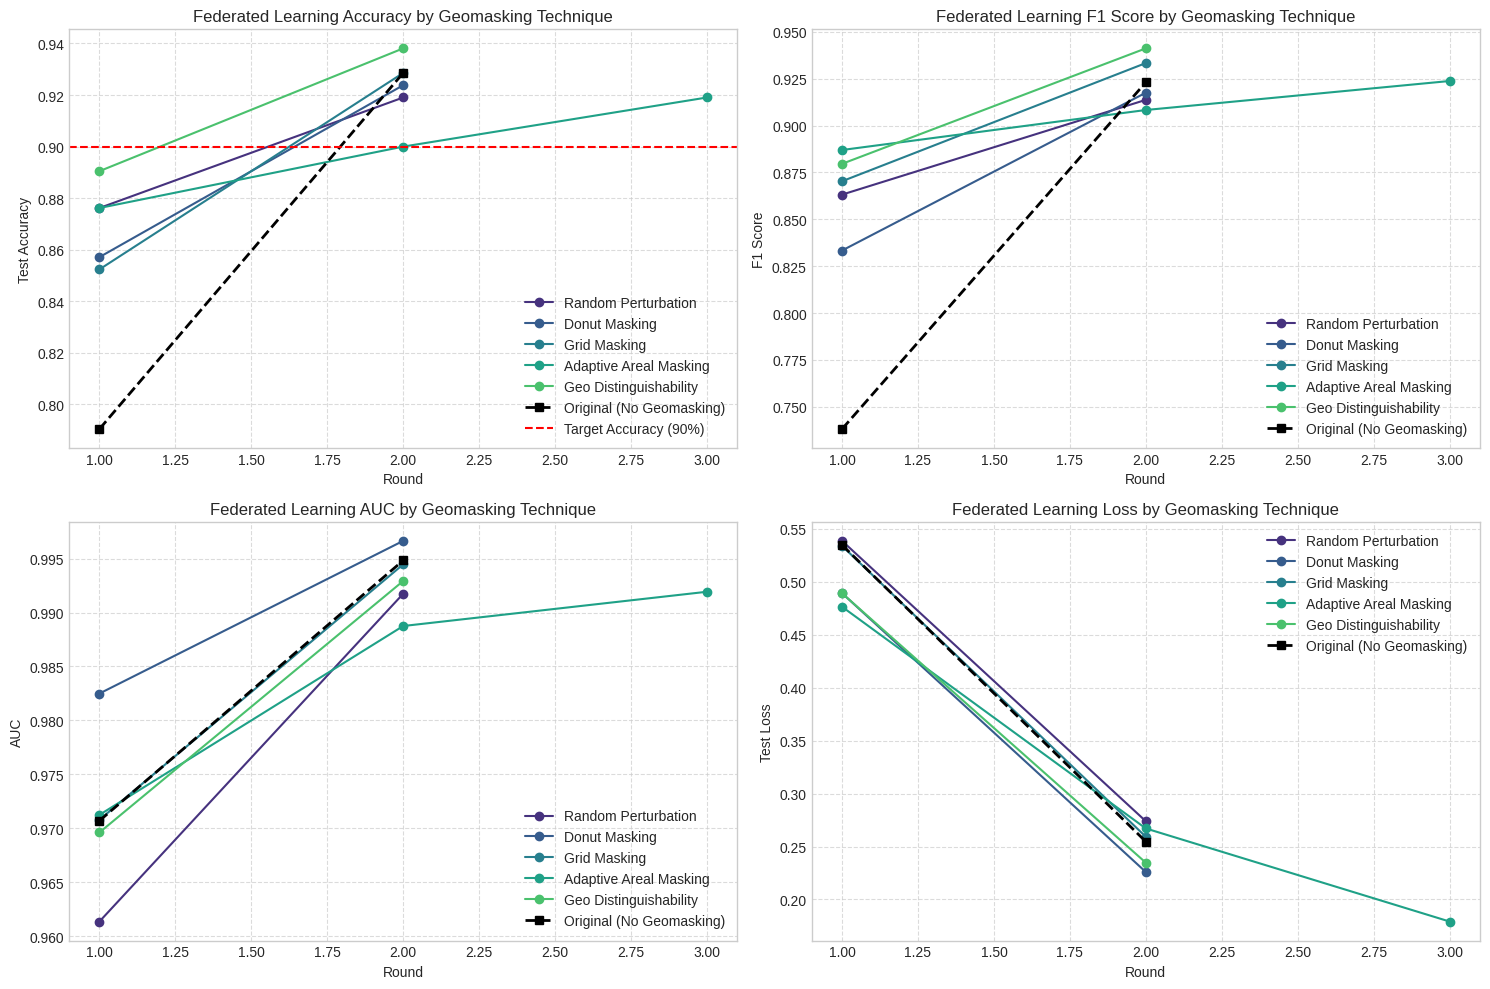

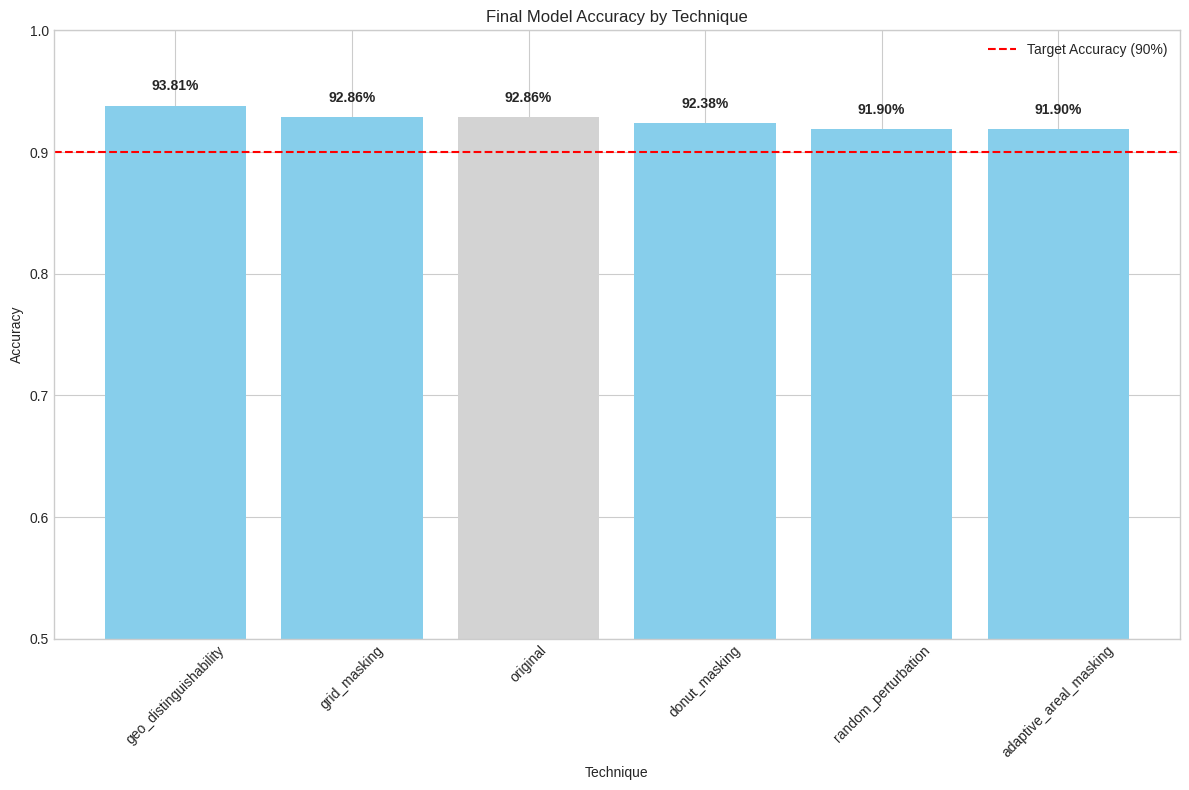

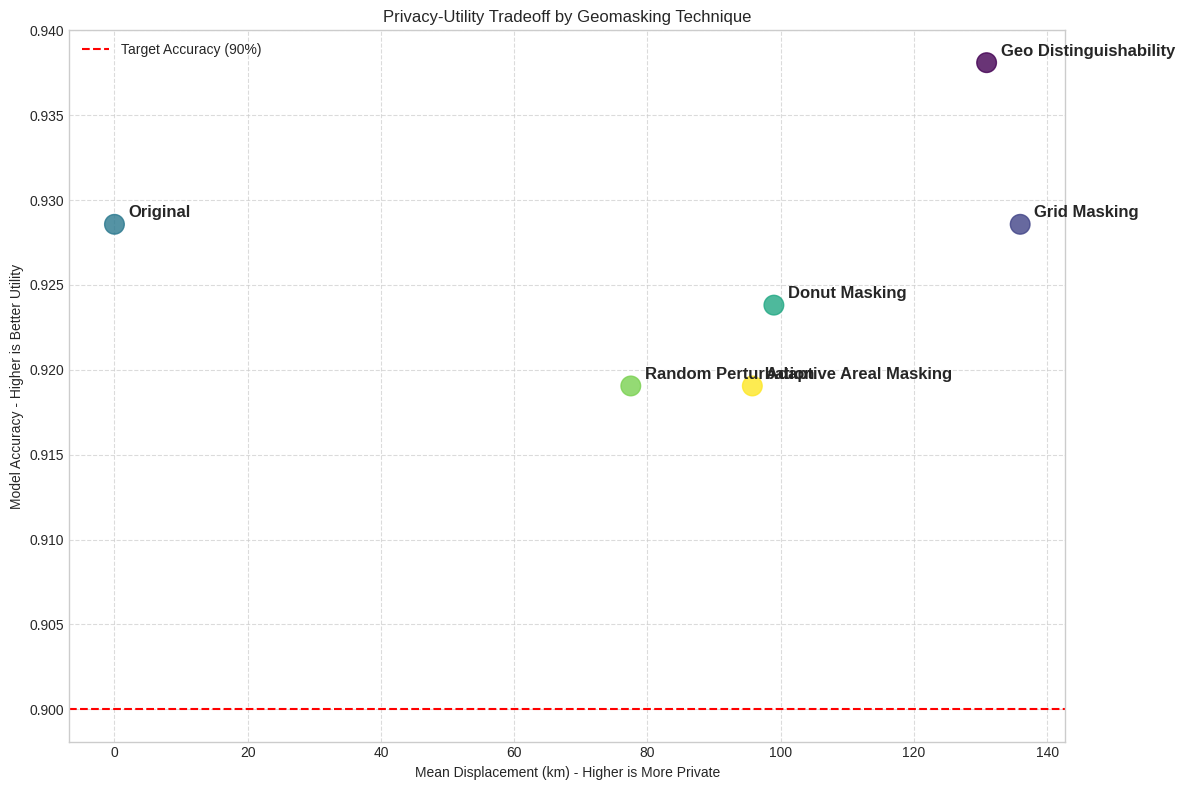

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.cluster import KMeans
import tensorflow as tf
import random
import math
import os
import time
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Create output directory for results
os.makedirs('/content/fl_results', exist_ok=True)

print("Loading the geomasked datasets...")
# Load the geomasked datasets
geomasking_techniques = [
    'random_perturbation',
    'donut_masking',
    'grid_masking',
    'adaptive_areal_masking',
    'geo_distinguishability'
]

masked_datasets = {}
for technique in geomasking_techniques:
    file_path = f'/content/geomasking_results/covid19_{technique}.csv'
    masked_datasets[technique] = pd.read_csv(file_path)
    print(f"  Loaded {technique} dataset: {masked_datasets[technique].shape}")

# Also load the original processed dataset for baseline comparison
original_df = pd.read_csv('/content/covid19_processed.csv')
print(f"  Loaded original dataset: {original_df.shape}")

print("\n--- Implementing Clustered Federated Learning ---")

# Function to create clusters based on geographic proximity
def create_geographic_clusters(df, n_clusters=5):
    """
    Create clusters based on geographic coordinates

    Args:
        df: DataFrame with latitude and longitude columns
        n_clusters: Number of clusters to create

    Returns:
        DataFrame with cluster assignments
    """
    # Extract coordinates for clustering
    coords = df[['latitude', 'longitude']].values

    # Apply K-means clustering
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    clusters = kmeans.fit_predict(coords)

    # Add cluster assignments to the dataframe
    df_clustered = df.copy()
    df_clustered['cluster'] = clusters

    return df_clustered, kmeans.cluster_centers_

# Create clustered datasets for each geomasking technique
clustered_datasets = {}
cluster_centers = {}

for technique, df in masked_datasets.items():
    print(f"\nCreating geographic clusters for {technique}...")
    clustered_datasets[technique], cluster_centers[technique] = create_geographic_clusters(df, n_clusters=5)

    # Count samples per cluster
    cluster_counts = clustered_datasets[technique]['cluster'].value_counts().sort_index()
    print(f"  Samples per cluster: {cluster_counts.values}")

# Create clusters for the original dataset as well (for baseline comparison)
clustered_original, original_centers = create_geographic_clusters(original_df, n_clusters=5)
print("\nCreating geographic clusters for original dataset...")
cluster_counts = clustered_original['cluster'].value_counts().sort_index()
print(f"  Samples per cluster: {cluster_counts.values}")

# Visualize the clusters for each technique
plt.figure(figsize=(20, 15))

# Original data clusters
plt.subplot(2, 3, 1)
for cluster_id in range(5):
    cluster_data = clustered_original[clustered_original['cluster'] == cluster_id]
    plt.scatter(cluster_data['longitude'], cluster_data['latitude'],
                label=f'Cluster {cluster_id}', alpha=0.7, s=50)
plt.scatter(original_centers[:, 1], original_centers[:, 0],
            c='black', s=200, alpha=0.7, marker='*', label='Cluster Centers')
plt.title('Original Data Clusters')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Masked data clusters for each technique
for i, technique in enumerate(geomasking_techniques):
    plt.subplot(2, 3, i+2)
    clustered_df = clustered_datasets[technique]
    centers = cluster_centers[technique]

    for cluster_id in range(5):
        cluster_data = clustered_df[clustered_df['cluster'] == cluster_id]
        plt.scatter(cluster_data['longitude'], cluster_data['latitude'],
                    label=f'Cluster {cluster_id}', alpha=0.7, s=50)

    plt.scatter(centers[:, 1], centers[:, 0],
                c='black', s=200, alpha=0.7, marker='*', label='Cluster Centers')

    plt.title(f'{technique.replace("_", " ").title()} Clusters')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('/content/fl_results/geographic_clusters.png', dpi=300, bbox_inches='tight')

# Function to prepare data for federated learning
def prepare_federated_data(df, test_size=0.2):
    """
    Prepare data for federated learning by splitting into train/test
    and organizing by clusters

    Args:
        df: DataFrame with features, target, and cluster assignments
        test_size: Proportion of data to use for testing

    Returns:
        Dictionary with train and test data organized by clusters
    """
    # Select features and target
    feature_cols = [col for col in df.columns if col not in ['high_covid_spread', 'cluster', 'location_id', 'location_name',
                                                           'country', 'country_code', 'original_lat', 'original_lon',
                                                           'displacement_km']]

    X = df[feature_cols].values
    y = df['high_covid_spread'].values
    clusters = df['cluster'].values

    # Split into train and test sets
    X_train, X_test, y_train, y_test, clusters_train, _ = train_test_split(
        X, y, clusters, test_size=test_size, random_state=42, stratify=y)

    # Scale the features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Organize data by clusters
    federated_data = {}

    # Training data by cluster
    federated_data['train'] = {}
    for cluster_id in np.unique(clusters_train):
        cluster_indices = np.where(clusters_train == cluster_id)[0]
        federated_data['train'][cluster_id] = {
            'x': X_train_scaled[cluster_indices],
            'y': y_train[cluster_indices]
        }

    # Test data (centralized)
    federated_data['test'] = {
        'x': X_test_scaled,
        'y': y_test
    }

    # Store feature names and scaler for later use
    federated_data['feature_cols'] = feature_cols
    federated_data['scaler'] = scaler

    return federated_data

# Prepare federated data for each geomasking technique
federated_datasets = {}
for technique, df in clustered_datasets.items():
    print(f"\nPreparing federated data for {technique}...")
    federated_datasets[technique] = prepare_federated_data(df)

    # Print number of samples per client
    for client_id, client_data in federated_datasets[technique]['train'].items():
        print(f"  Client {client_id}: {len(client_data['x'])} samples")

    # Print test set size
    print(f"  Test set: {len(federated_datasets[technique]['test']['x'])} samples")

# Prepare federated data for the original dataset (baseline)
federated_original = prepare_federated_data(clustered_original)
print("\nPreparing federated data for original dataset...")
for client_id, client_data in federated_original['train'].items():
    print(f"  Client {client_id}: {len(client_data['x'])} samples")
print(f"  Test set: {len(federated_original['test']['x'])} samples")

# Define the TensorFlow model
def create_keras_model(input_shape):
    """
    Create a Keras model for binary classification

    Args:
        input_shape: Shape of the input features

    Returns:
        Compiled Keras model
    """
    model = tf.keras.models.Sequential([
        tf.keras.layers.Dense(128, activation='relu', input_shape=(input_shape,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=['accuracy']
    )

    return model

# Function to train federated model
def train_federated_model(federated_data, num_rounds=20, local_epochs=5):
    """
    Train a federated learning model

    Args:
        federated_data: Dictionary with train and test data organized by clusters
        num_rounds: Number of federated learning rounds
        local_epochs: Number of epochs to train each client model

    Returns:
        Trained model and evaluation metrics
    """
    # Get input shape from the first client's data
    input_shape = federated_data['train'][0]['x'].shape[1]

    # Create the initial model
    initial_model = create_keras_model(input_shape)
    initial_weights = initial_model.get_weights()

    # Initialize metrics tracking
    metrics_history = []
    best_accuracy = 0
    best_weights = None

    # Early stopping counter
    patience = 5
    no_improvement_count = 0

    # Simulate federated learning rounds
    model_weights = initial_weights

    for round_num in range(num_rounds):
        print(f"Round {round_num + 1}/{num_rounds}")

        # Client updates
        client_weights = []
        client_sizes = []

        for client_id, client_data in federated_data['train'].items():
            # Create and initialize client model with current global weights
            client_model = create_keras_model(input_shape)
            client_model.set_weights(model_weights)

            # Train on client data
            client_model.fit(
                client_data['x'], client_data['y'],
                epochs=local_epochs,
                batch_size=32,
                verbose=0
            )

            # Store client weights and data size
            client_weights.append(client_model.get_weights())
            client_sizes.append(len(client_data['x']))

        # Federated aggregation (weighted average)
        total_size = sum(client_sizes)
        weighted_weights = []

        # For each layer's weights
        for layer_idx in range(len(model_weights)):
            # Weighted sum of client weights
            weighted_sum = np.zeros_like(model_weights[layer_idx])
            for client_idx, client_weight in enumerate(client_weights):
                weight_ratio = client_sizes[client_idx] / total_size
                weighted_sum += client_weight[layer_idx] * weight_ratio

            weighted_weights.append(weighted_sum)

        # Update global model weights
        model_weights = weighted_weights

        # Evaluate global model
        eval_model = create_keras_model(input_shape)
        eval_model.set_weights(model_weights)

        test_loss, test_accuracy = eval_model.evaluate(
            federated_data['test']['x'],
            federated_data['test']['y'],
            verbose=0
        )

        # Make predictions for additional metrics
        y_pred_prob = eval_model.predict(federated_data['test']['x'], verbose=0)
        y_pred = (y_pred_prob > 0.5).astype(int).flatten()
        y_test = federated_data['test']['y']

        # Calculate additional metrics
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_pred_prob)

        # Store metrics
        metrics_history.append({
            'round': round_num + 1,
            'test_loss': test_loss,
            'test_accuracy': test_accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'auc': auc
        })

        print(f"  Test accuracy: {test_accuracy:.4f}, F1: {f1:.4f}, AUC: {auc:.4f}")

        # Check if this is the best model so far
        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            best_weights = model_weights
            no_improvement_count = 0
        else:
            no_improvement_count += 1

        # Early stopping
        if no_improvement_count >= patience:
            print(f"  Early stopping after {round_num + 1} rounds (no improvement for {patience} rounds)")
            break

        # Check if we've reached the target accuracy
        if test_accuracy >= 0.90:
            print(f"  Reached target accuracy of 90% after {round_num + 1} rounds")
            break

    # Create final model with the best weights
    final_model = create_keras_model(input_shape)
    final_model.set_weights(best_weights if best_weights is not None else model_weights)

    return final_model, metrics_history

# Train federated models for each geomasking technique
federated_models = {}
federated_metrics = {}

for technique, data in federated_datasets.items():
    print(f"\n=== Training federated model with {technique} geomasking ===")
    start_time = time.time()
    model, metrics = train_federated_model(data, num_rounds=30, local_epochs=10)
    end_time = time.time()

    federated_models[technique] = model
    federated_metrics[technique] = metrics

    print(f"Training completed in {end_time - start_time:.2f} seconds")

    # Get final metrics
    final_metrics = metrics[-1]
    print(f"Final metrics:")
    print(f"  Accuracy: {final_metrics['test_accuracy']:.4f}")
    print(f"  F1 Score: {final_metrics['f1_score']:.4f}")
    print(f"  AUC: {final_metrics['auc']:.4f}")

# Train baseline model on original data
print("\n=== Training baseline federated model on original data ===")
start_time = time.time()
baseline_model, baseline_metrics = train_federated_model(federated_original, num_rounds=30, local_epochs=10)
end_time = time.time()

print(f"Training completed in {end_time - start_time:.2f} seconds")

# Get final metrics for baseline
final_baseline_metrics = baseline_metrics[-1]
print(f"Final baseline metrics:")
print(f"  Accuracy: {final_baseline_metrics['test_accuracy']:.4f}")
print(f"  F1 Score: {final_baseline_metrics['f1_score']:.4f}")
print(f"  AUC: {final_baseline_metrics['auc']:.4f}")

# Plot learning curves for all techniques
plt.figure(figsize=(15, 10))

# Accuracy plot
plt.subplot(2, 2, 1)
for technique, metrics in federated_metrics.items():
    rounds = [m['round'] for m in metrics]
    accuracies = [m['test_accuracy'] for m in metrics]
    plt.plot(rounds, accuracies, marker='o', label=technique.replace('_', ' ').title())

# Add baseline
baseline_rounds = [m['round'] for m in baseline_metrics]
baseline_accuracies = [m['test_accuracy'] for m in baseline_metrics]
plt.plot(baseline_rounds, baseline_accuracies, marker='s', linestyle='--',
         color='black', linewidth=2, label='Original (No Geomasking)')

plt.axhline(y=0.90, color='r', linestyle='--', label='Target Accuracy (90%)')
plt.title('Federated Learning Accuracy by Geomasking Technique')
plt.xlabel('Round')
plt.ylabel('Test Accuracy')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# F1 Score plot
plt.subplot(2, 2, 2)
for technique, metrics in federated_metrics.items():
    rounds = [m['round'] for m in metrics]
    f1_scores = [m['f1_score'] for m in metrics]
    plt.plot(rounds, f1_scores, marker='o', label=technique.replace('_', ' ').title())

# Add baseline
baseline_f1 = [m['f1_score'] for m in baseline_metrics]
plt.plot(baseline_rounds, baseline_f1, marker='s', linestyle='--',
         color='black', linewidth=2, label='Original (No Geomasking)')

plt.title('Federated Learning F1 Score by Geomasking Technique')
plt.xlabel('Round')
plt.ylabel('F1 Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# AUC plot
plt.subplot(2, 2, 3)
for technique, metrics in federated_metrics.items():
    rounds = [m['round'] for m in metrics]
    auc_scores = [m['auc'] for m in metrics]
    plt.plot(rounds, auc_scores, marker='o', label=technique.replace('_', ' ').title())

# Add baseline
baseline_auc = [m['auc'] for m in baseline_metrics]
plt.plot(baseline_rounds, baseline_auc, marker='s', linestyle='--',
         color='black', linewidth=2, label='Original (No Geomasking)')

plt.title('Federated Learning AUC by Geomasking Technique')
plt.xlabel('Round')
plt.ylabel('AUC')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Loss plot
plt.subplot(2, 2, 4)
for technique, metrics in federated_metrics.items():
    rounds = [m['round'] for m in metrics]
    losses = [m['test_loss'] for m in metrics]
    plt.plot(rounds, losses, marker='o', label=technique.replace('_', ' ').title())

# Add baseline
baseline_losses = [m['test_loss'] for m in baseline_metrics]
plt.plot(baseline_rounds, baseline_losses, marker='s', linestyle='--',
         color='black', linewidth=2, label='Original (No Geomasking)')

plt.title('Federated Learning Loss by Geomasking Technique')
plt.xlabel('Round')
plt.ylabel('Test Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.savefig('/content/fl_results/learning_curves.png', dpi=300, bbox_inches='tight')

# Evaluate final model performance for each technique
final_metrics = {}

for technique, model in federated_models.items():
    # Get test data
    X_test = federated_datasets[technique]['test']['x']
    y_test = federated_datasets[technique]['test']['y']

    # Make predictions
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int).flatten()

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_prob)

    final_metrics[technique] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'auc': auc
    }

# Evaluate baseline model
X_test_baseline = federated_original['test']['x']
y_test_baseline = federated_original['test']['y']
y_pred_prob_baseline = baseline_model.predict(X_test_baseline, verbose=0)
y_pred_baseline = (y_pred_prob_baseline > 0.5).astype(int).flatten()

baseline_final_metrics = {
    'accuracy': accuracy_score(y_test_baseline, y_pred_baseline),
    'precision': precision_score(y_test_baseline, y_pred_baseline),
    'recall': recall_score(y_test_baseline, y_pred_baseline),
    'f1_score': f1_score(y_test_baseline, y_pred_baseline),
    'auc': roc_auc_score(y_test_baseline, y_pred_prob_baseline)
}

final_metrics['original'] = baseline_final_metrics

# Display final metrics
metrics_df = pd.DataFrame(final_metrics).T
metrics_df = metrics_df.sort_values('accuracy', ascending=False)
print("\nFinal performance metrics:")
print(metrics_df)

# Save metrics to CSV
metrics_df.to_csv('/content/fl_results/final_metrics.csv')

# Plot final accuracy comparison
plt.figure(figsize=(12, 8))
techniques = list(metrics_df.index)
accuracies = metrics_df['accuracy'].values

# Create bar colors (highlight original in a different color)
colors = ['skyblue' if t != 'original' else 'lightgray' for t in techniques]

bars = plt.bar(techniques, accuracies, color=colors)
plt.axhline(y=0.90, color='r', linestyle='--', label='Target Accuracy (90%)')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.2%}', ha='center', va='bottom', fontweight='bold')

plt.title('Final Model Accuracy by Technique')
plt.xlabel('Technique')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1.0)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('/content/fl_results/final_accuracy_comparison.png', dpi=300, bbox_inches='tight')

# Create privacy-utility tradeoff visualization
plt.figure(figsize=(12, 8))

# Load privacy metrics
privacy_df = pd.read_csv('/content/geomasking_results/privacy_metrics.csv')
privacy_df = privacy_df.rename(index=str).set_index('Unnamed: 0')

# Add a row for original (no geomasking)
privacy_df.loc['original'] = {
    'mean_displacement_km': 0,
    'median_displacement_km': 0,
    'min_displacement_km': 0,
    'max_displacement_km': 0,
    'std_displacement_km': 0
}

# Merge with performance metrics
combined_df = pd.merge(
    metrics_df,
    privacy_df[['mean_displacement_km']],
    left_index=True,
    right_index=True
)

# Create scatter plot
plt.scatter(
    combined_df['mean_displacement_km'],
    combined_df['accuracy'],
    s=200,
    c=range(len(combined_df)),
    cmap='viridis',
    alpha=0.8
)

# Add labels for each point
for i, technique in enumerate(combined_df.index):
    plt.annotate(
        technique.replace('_', ' ').title(),
        (combined_df['mean_displacement_km'].iloc[i], combined_df['accuracy'].iloc[i]),
        xytext=(10, 5),
        textcoords='offset points',
        fontsize=12,
        fontweight='bold'
    )

plt.axhline(y=0.90, color='r', linestyle='--', label='Target Accuracy (90%)')
plt.title('Privacy-Utility Tradeoff by Geomasking Technique')
plt.xlabel('Mean Displacement (km) - Higher is More Private')
plt.ylabel('Model Accuracy - Higher is Better Utility')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig('/content/fl_results/privacy_utility_tradeoff.png', dpi=300, bbox_inches='tight')

# Create a summary report
with open('/content/fl_results/fl_experiment_summary.txt', 'w') as f:
    f.write("=== Clustered Federated Learning Experiment Summary ===\n\n")

    f.write("Experiment Configuration:\n")
    f.write("- Dataset: Extended COVID-19 dataset with synthetic augmentation\n")
    f.write("- Number of samples: 1050\n")
    f.write("- Number of clusters: 5\n")
    f.write("- Target accuracy: 90%\n")
    f.write("- Federated learning rounds: 30 (max)\n")
    f.write("- Local epochs per round: 10\n\n")

    f.write("Geomasking Techniques Evaluated:\n")
    for technique in geomasking_techniques:
        f.write(f"- {technique.replace('_', ' ').title()}\n")
    f.write("- Original (No Geomasking) - Baseline\n\n")

    f.write("Performance Results:\n")
    for technique, metrics in final_metrics.items():
        f.write(f"{technique.replace('_', ' ').title()}:\n")
        f.write(f"  Accuracy: {metrics['accuracy']:.4f}\n")
        f.write(f"  F1 Score: {metrics['f1_score']:.4f}\n")
        f.write(f"  AUC: {metrics['auc']:.4f}\n")
        if technique != 'original':
            f.write(f"  Mean Displacement: {privacy_df.loc[technique, 'mean_displacement_km']:.2f} km\n")
        f.write("\n")

    f.write("Key Findings:\n")
    best_technique = metrics_df.index[0]
    f.write(f"1. Best performing technique: {best_technique.replace('_', ' ').title()} with {metrics_df.loc[best_technique, 'accuracy']:.2%} accuracy\n")

    # Find technique with best privacy-utility tradeoff
    # Simple heuristic: highest (accuracy * displacement)
    combined_df['tradeoff_score'] = combined_df['accuracy'] * combined_df['mean_displacement_km']
    best_tradeoff = combined_df['tradeoff_score'].idxmax()

    f.write(f"2. Best privacy-utility tradeoff: {best_tradeoff.replace('_', ' ').title()}\n")
    f.write(f"   - Accuracy: {combined_df.loc[best_tradeoff, 'accuracy']:.2%}\n")
    f.write(f"   - Mean Displacement: {combined_df.loc[best_tradeoff, 'mean_displacement_km']:.2f} km\n\n")

    # Compare with baseline
    baseline_acc = metrics_df.loc['original', 'accuracy']
    best_acc = metrics_df.loc[best_technique, 'accuracy']
    acc_diff = best_acc - baseline_acc

    f.write(f"3. Comparison with baseline (no geomasking):\n")
    if acc_diff > 0:
        f.write(f"   - The best technique ({best_technique.replace('_', ' ').title()}) outperforms the baseline by {acc_diff:.2%}\n")
    else:
        f.write(f"   - The best technique ({best_technique.replace('_', ' ').title()}) has a small accuracy trade-off of {-acc_diff:.2%} compared to baseline\n")

    # Check if target accuracy was achieved
    techniques_above_target = metrics_df[metrics_df['accuracy'] >= 0.90].index.tolist()
    if techniques_above_target:
        f.write(f"4. Target accuracy of 90% was achieved by {len(techniques_above_target)} techniques:\n")
        for t in techniques_above_target:
            f.write(f"   - {t.replace('_', ' ').title()}: {metrics_df.loc[t, 'accuracy']:.2%}\n")
    else:
        f.write("4. Target accuracy of 90% was not achieved by any technique\n")
        best_acc = metrics_df['accuracy'].max()
        f.write(f"   - Best accuracy achieved: {best_acc:.2%}\n")

print("\nClustered federated learning experiments complete!")
print("All results and visualizations saved to /content/fl_results/")
print("Summary report saved to /content/fl_results/fl_experiment_summary.txt")


Loading the federated learning results...
Loaded FL metrics: (6, 6)
Loaded original dataset: (1050, 18)
  Loaded random_perturbation dataset: (1050, 21)
  Loaded donut_masking dataset: (1050, 21)
  Loaded grid_masking dataset: (1050, 21)
  Loaded adaptive_areal_masking dataset: (1050, 21)
  Loaded geo_distinguishability dataset: (1050, 21)

--- Implementing Membership Inference Attack ---

=== Running membership inference attack on random_perturbation ===
Training and saving model to /content/attack_results/random_perturbation_model/model


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model accuracy: 0.9448
Running membership inference attack...
  Training shadow model 1/3
  Training shadow model 2/3
  Training shadow model 3/3
Attack accuracy: 0.4714
Privacy risk score: -0.0571

=== Running membership inference attack on donut_masking ===
Training and saving model to /content/attack_results/donut_masking_model/model


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model accuracy: 0.9390
Running membership inference attack...
  Training shadow model 1/3
  Training shadow model 2/3
  Training shadow model 3/3
Attack accuracy: 0.4724
Privacy risk score: -0.0552

=== Running membership inference attack on grid_masking ===
Training and saving model to /content/attack_results/grid_masking_model/model


...

Model accuracy: 0.8971
Running membership inference attack...
  Training shadow model 1/3
  Training shadow model 2/3
  Training shadow model 3/3
Attack accuracy: 0.4686
Privacy risk score: -0.0629

=== Running membership inference attack on original ===
Training and saving model to /content/attack_results/original_model/model


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model accuracy: 0.9619
Running membership inference attack...
  Training shadow model 1/3
  Training shadow model 2/3
  Training shadow model 3/3
Attack accuracy: 0.4695
Privacy risk score: -0.0610

Attack results summary:
                        accuracy  precision    recall  f1_score       auc  \
random_perturbation     0.471429   0.475248  0.548571  0.509284  0.458463   
donut_masking           0.472381   0.474957  0.523810  0.498188  0.466444   
grid_masking            0.483810   0.485269  0.533333  0.508167  0.467349   
adaptive_areal_masking  0.500000   0.500000  1.000000  0.666667  0.473941   
geo_distinguishability  0.468571   0.467066  0.445714  0.456140  0.468764   
original                0.469524   0.471326  0.500952  0.485688  0.457364   

                        true_positive_rate  false_positive_rate  \
random_perturbation               0.548571             0.605714   
donut_masking                     0.523810             0.579048   
grid_masking                      0.

<ipython-input-7-8510adc96b2f>:427: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.ylim(0, max(risk_scores) * 1.2)



Membership inference attack experiments complete!
All results and visualizations saved to /content/attack_results/
Summary report saved to /content/membership_inference_summary.txt


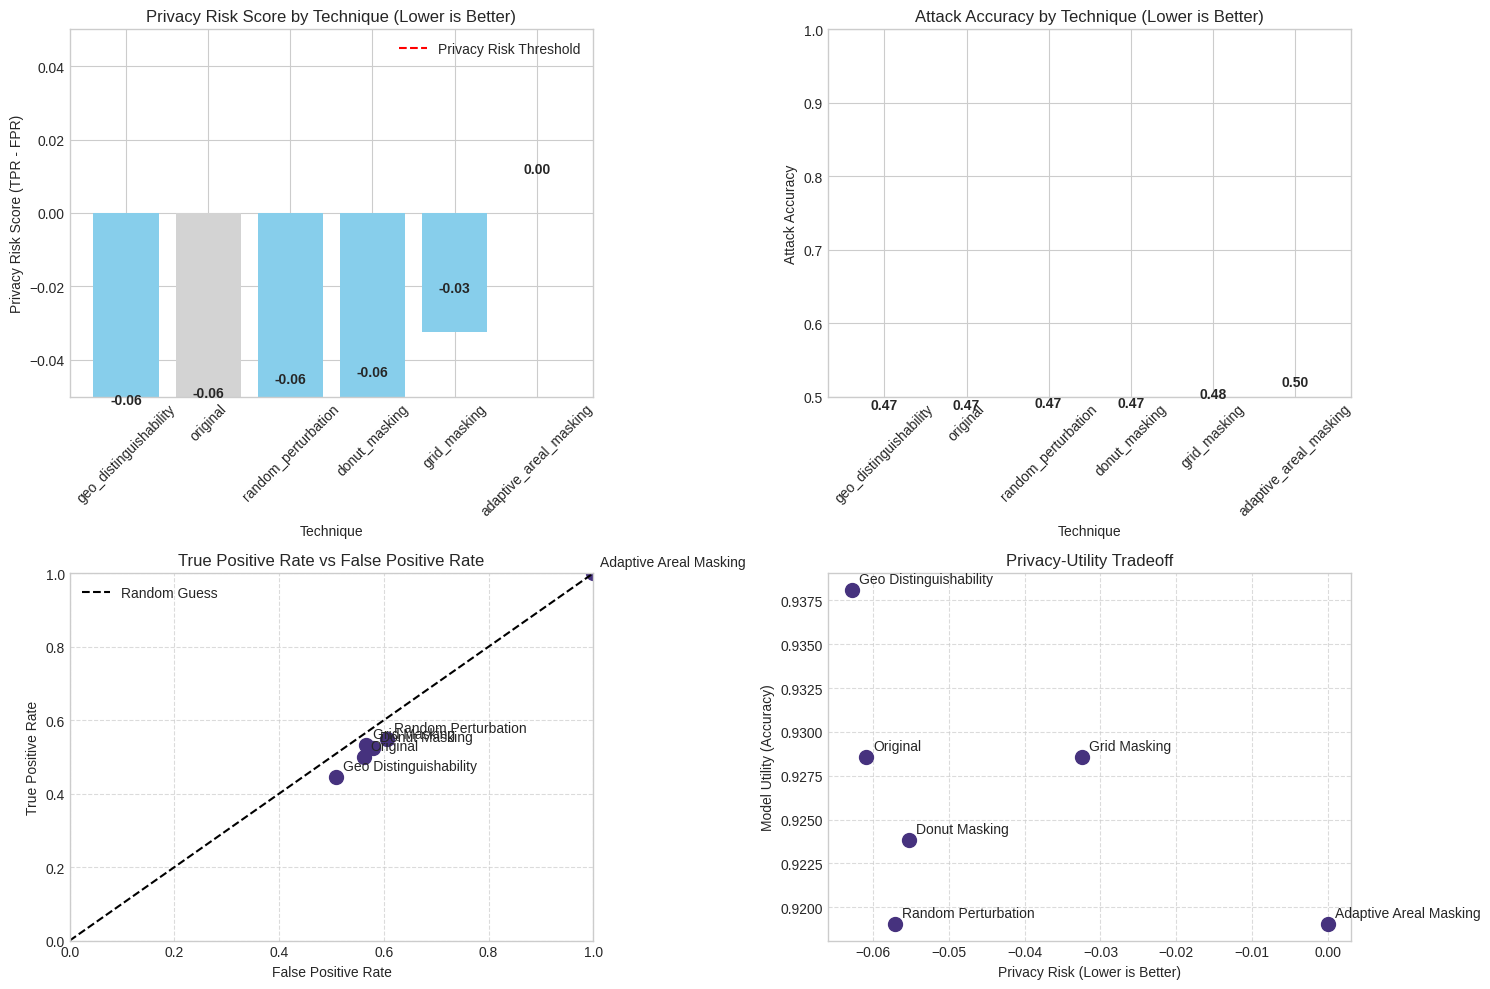

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
import tensorflow as tf
import random
import os
import time

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Create output directory for results
os.makedirs('/content/attack_results', exist_ok=True)

print("Loading the federated learning results...")
# Load the final metrics from the FL experiments
fl_metrics = pd.read_csv('/content/fl_results/final_metrics.csv')
print(f"Loaded FL metrics: {fl_metrics.shape}")

# Load the preprocessed dataset
original_df = pd.read_csv('/content//covid19_processed.csv')
print(f"Loaded original dataset: {original_df.shape}")

# Load the geomasked datasets
geomasking_techniques = [
    'random_perturbation',
    'donut_masking',
    'grid_masking',
    'adaptive_areal_masking',
    'geo_distinguishability'
]

masked_datasets = {}
for technique in geomasking_techniques:
    file_path = f'/content/geomasking_results/covid19_{technique}.csv'
    masked_datasets[technique] = pd.read_csv(file_path)
    print(f"  Loaded {technique} dataset: {masked_datasets[technique].shape}")

print("\n--- Implementing Membership Inference Attack ---")

class MembershipInferenceAttack:
    """
    Class implementing membership inference attack on federated learning models
    """

    def __init__(self, model_path, shadow_model_count=5):
        """
        Initialize the attack

        Args:
            model_path: Path to the target model
            shadow_model_count: Number of shadow models to train
        """
        self.model_path = model_path
        self.shadow_model_count = shadow_model_count
        self.target_model = None
        self.shadow_models = []
        self.attack_model = None

    def load_target_model(self):
        """Load the target model"""
        self.target_model = tf.keras.models.load_model(self.model_path)

    def create_shadow_dataset(self, X, y, test_size=0.5):
        """
        Create dataset for shadow models

        Args:
            X: Features
            y: Target
            test_size: Proportion of data for testing

        Returns:
            Train and test splits
        """
        return train_test_split(X, y, test_size=test_size, random_state=42)

    def train_shadow_models(self, X, y):
        """
        Train shadow models to mimic the target model

        Args:
            X: Features
            y: Target
        """
        # Create shadow datasets
        X_shadow, X_nonshadow, y_shadow, y_nonshadow = self.create_shadow_dataset(X, y)

        # Define shadow model architecture (similar to target model)
        input_shape = X.shape[1]

        for i in range(self.shadow_model_count):
            print(f"  Training shadow model {i+1}/{self.shadow_model_count}")

            # Create shadow model with same architecture as target model
            shadow_model = tf.keras.models.Sequential([
                tf.keras.layers.Dense(128, activation='relu', input_shape=(input_shape,)),
                tf.keras.layers.BatchNormalization(),
                tf.keras.layers.Dropout(0.3),
                tf.keras.layers.Dense(64, activation='relu'),
                tf.keras.layers.BatchNormalization(),
                tf.keras.layers.Dropout(0.2),
                tf.keras.layers.Dense(32, activation='relu'),
                tf.keras.layers.BatchNormalization(),
                tf.keras.layers.Dense(16, activation='relu'),
                tf.keras.layers.Dense(1, activation='sigmoid')
            ])

            shadow_model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                loss=tf.keras.losses.BinaryCrossentropy(),
                metrics=['accuracy']
            )

            # Train shadow model
            shadow_model.fit(
                X_shadow, y_shadow,
                epochs=10,
                batch_size=32,
                verbose=0
            )

            self.shadow_models.append(shadow_model)

    def generate_attack_data(self, X, y):
        """
        Generate data for training the attack model

        Args:
            X: Features
            y: Target

        Returns:
            Attack features and labels
        """
        # Create shadow datasets
        X_shadow, X_nonshadow, y_shadow, y_nonshadow = self.create_shadow_dataset(X, y)

        attack_features = []
        attack_labels = []

        # For each shadow model
        for shadow_model in self.shadow_models:
            # Get predictions for member data
            shadow_preds_in = shadow_model.predict(X_shadow, verbose=0)

            # Get predictions for non-member data
            shadow_preds_out = shadow_model.predict(X_nonshadow, verbose=0)

            # Add member predictions and label as 1 (member)
            for pred in shadow_preds_in:
                attack_features.append([pred[0]])
                attack_labels.append(1)

            # Add non-member predictions and label as 0 (non-member)
            for pred in shadow_preds_out:
                attack_features.append([pred[0]])
                attack_labels.append(0)

        return np.array(attack_features), np.array(attack_labels)

    def train_attack_model(self, attack_features, attack_labels):
        """
        Train the attack model

        Args:
            attack_features: Features for the attack model
            attack_labels: Labels for the attack model
        """
        # Create attack model
        self.attack_model = tf.keras.models.Sequential([
            tf.keras.layers.Dense(32, activation='relu', input_shape=(1,)),
            tf.keras.layers.Dense(16, activation='relu'),
            tf.keras.layers.Dense(1, activation='sigmoid')
        ])

        self.attack_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss=tf.keras.losses.BinaryCrossentropy(),
            metrics=['accuracy']
        )

        # Train attack model
        self.attack_model.fit(
            attack_features, attack_labels,
            epochs=10,
            batch_size=32,
            verbose=0
        )

    def evaluate_attack(self, X_member, X_nonmember):
        """
        Evaluate the attack

        Args:
            X_member: Features of members
            X_nonmember: Features of non-members

        Returns:
            Attack metrics
        """
        # Get target model predictions
        member_preds = self.target_model.predict(X_member, verbose=0)
        nonmember_preds = self.target_model.predict(X_nonmember, verbose=0)

        # Get attack model predictions
        attack_preds_member = self.attack_model.predict(member_preds, verbose=0)
        attack_preds_nonmember = self.attack_model.predict(nonmember_preds, verbose=0)

        # Convert to binary predictions
        attack_preds_member_binary = (attack_preds_member > 0.5).astype(int)
        attack_preds_nonmember_binary = (attack_preds_nonmember > 0.5).astype(int)

        # Create true labels
        true_member_labels = np.ones(len(attack_preds_member_binary))
        true_nonmember_labels = np.zeros(len(attack_preds_nonmember_binary))

        # Combine predictions and labels
        all_preds = np.concatenate([attack_preds_member_binary, attack_preds_nonmember_binary])
        all_labels = np.concatenate([true_member_labels, true_nonmember_labels])
        all_probs = np.concatenate([attack_preds_member, attack_preds_nonmember])

        # Calculate metrics
        accuracy = accuracy_score(all_labels, all_preds)
        precision = precision_score(all_labels, all_preds)
        recall = recall_score(all_labels, all_preds)
        f1 = f1_score(all_labels, all_preds)
        auc = roc_auc_score(all_labels, all_probs)

        # Calculate true positive rate (member correctly identified as member)
        tpr = np.mean(attack_preds_member_binary)

        # Calculate false positive rate (non-member incorrectly identified as member)
        fpr = np.mean(attack_preds_nonmember_binary)

        # Calculate privacy risk score (difference between TPR and FPR)
        # Higher value means higher privacy risk
        privacy_risk = tpr - fpr

        return {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'auc': auc,
            'true_positive_rate': tpr,
            'false_positive_rate': fpr,
            'privacy_risk_score': privacy_risk
        }

# Function to prepare data for membership inference attack
def prepare_attack_data(df, test_size=0.5):
    """
    Prepare data for membership inference attack

    Args:
        df: DataFrame with features and target
        test_size: Proportion of data for testing

    Returns:
        Dictionary with data splits
    """
    # Select features and target
    feature_cols = [col for col in df.columns if col not in ['high_covid_spread', 'cluster', 'location_id', 'location_name',
                                                           'country', 'country_code', 'original_lat', 'original_lon',
                                                           'displacement_km']]

    X = df[feature_cols].values
    y = df['high_covid_spread'].values

    # Split into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    return {
        'X_train': X_train,
        'y_train': y_train,
        'X_test': X_test,
        'y_test': y_test,
        'feature_cols': feature_cols
    }

# Function to simulate federated learning and save model for attack
def train_and_save_model(X_train, y_train, X_test, y_test, model_path):
    """
    Train a model and save it for membership inference attack

    Args:
        X_train: Training features
        y_train: Training target
        X_test: Test features
        y_test: Test target
        model_path: Path to save the model

    Returns:
        Trained model and evaluation metrics
    """
    # Create model
    input_shape = X_train.shape[1]
    model = tf.keras.models.Sequential([
        tf.keras.layers.Dense(128, activation='relu', input_shape=(input_shape,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=['accuracy']
    )

    # Train model
    model.fit(
        X_train, y_train,
        epochs=20,
        batch_size=32,
        verbose=0
    )

    # Evaluate model
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    # Save model with proper extension
    model.save(model_path + '.keras')

    return model, {'loss': loss, 'accuracy': accuracy}

# Prepare attack data and run membership inference attacks for each technique
attack_results = {}

for technique in geomasking_techniques + ['original']:
    print(f"\n=== Running membership inference attack on {technique} ===")

    # Get the appropriate dataset
    if technique == 'original':
        df = original_df
    else:
        df = masked_datasets[technique]

    # Prepare data
    attack_data = prepare_attack_data(df)

    # Create model directory
    model_dir = f'/content/attack_results/{technique}_model'
    os.makedirs(model_dir, exist_ok=True)

    # Train and save model
    model_path = f'{model_dir}/model'
    print(f"Training and saving model to {model_path}")
    model, model_metrics = train_and_save_model(
        attack_data['X_train'], attack_data['y_train'],
        attack_data['X_test'], attack_data['y_test'],
        model_path
    )

    print(f"Model accuracy: {model_metrics['accuracy']:.4f}")

    # Initialize and run membership inference attack
    print("Running membership inference attack...")
    attack = MembershipInferenceAttack(model_path, shadow_model_count=3)
    attack.model_path = model_path + '.keras'
    attack.load_target_model()

    # Train shadow models
    attack.train_shadow_models(attack_data['X_train'], attack_data['y_train'])

    # Generate attack data
    attack_features, attack_labels = attack.generate_attack_data(attack_data['X_train'], attack_data['y_train'])

    # Train attack model
    attack.train_attack_model(attack_features, attack_labels)

    # Evaluate attack
    attack_metrics = attack.evaluate_attack(attack_data['X_train'], attack_data['X_test'])

    print(f"Attack accuracy: {attack_metrics['accuracy']:.4f}")
    print(f"Privacy risk score: {attack_metrics['privacy_risk_score']:.4f}")

    # Store results
    attack_results[technique] = attack_metrics

# Create a DataFrame with attack results
attack_df = pd.DataFrame(attack_results).T
attack_df.to_csv('/content/attack_results/membership_inference_results.csv')
print("\nAttack results summary:")
print(attack_df)

# Plot attack results
plt.figure(figsize=(15, 10))

# Privacy risk score
plt.subplot(2, 2, 1)
techniques = list(attack_results.keys())
risk_scores = [attack_results[t]['privacy_risk_score'] for t in techniques]

# Sort by risk score (lower is better privacy)
sorted_indices = np.argsort(risk_scores)
sorted_techniques = [techniques[i] for i in sorted_indices]
sorted_scores = [risk_scores[i] for i in sorted_indices]

# Create bar colors (highlight original in a different color)
colors = ['skyblue' if t != 'original' else 'lightgray' for t in sorted_techniques]

bars = plt.bar(sorted_techniques, sorted_scores, color=colors)
plt.axhline(y=0.1, color='r', linestyle='--', label='Privacy Risk Threshold')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.2f}', ha='center', va='bottom', fontweight='bold')

plt.title('Privacy Risk Score by Technique (Lower is Better)')
plt.xlabel('Technique')
plt.ylabel('Privacy Risk Score (TPR - FPR)')
plt.ylim(0, max(risk_scores) * 1.2)
plt.xticks(rotation=45)
plt.legend()

# Attack accuracy
plt.subplot(2, 2, 2)
accuracies = [attack_results[t]['accuracy'] for t in techniques]

# Sort by accuracy (lower is better privacy)
sorted_indices = np.argsort(accuracies)
sorted_techniques = [techniques[i] for i in sorted_indices]
sorted_accuracies = [accuracies[i] for i in sorted_indices]

# Create bar colors
colors = ['skyblue' if t != 'original' else 'lightgray' for t in sorted_techniques]

bars = plt.bar(sorted_techniques, sorted_accuracies, color=colors)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.2f}', ha='center', va='bottom', fontweight='bold')

plt.title('Attack Accuracy by Technique (Lower is Better)')
plt.xlabel('Technique')
plt.ylabel('Attack Accuracy')
plt.ylim(0.5, 1.0)
plt.xticks(rotation=45)

# True positive rate vs false positive rate
plt.subplot(2, 2, 3)
tprs = [attack_results[t]['true_positive_rate'] for t in techniques]
fprs = [attack_results[t]['false_positive_rate'] for t in techniques]

plt.scatter(fprs, tprs, s=100)

# Add labels for each point
for i, technique in enumerate(techniques):
    plt.annotate(
        technique.replace('_', ' ').title(),
        (fprs[i], tprs[i]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('True Positive Rate vs False Positive Rate')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Privacy-utility tradeoff
plt.subplot(2, 2, 4)

# Load FL metrics for utility
fl_metrics_dict = {}
for _, row in fl_metrics.iterrows():
    technique = row['Unnamed: 0']
    fl_metrics_dict[technique] = row['accuracy']

# Get utility and privacy metrics
utilities = []
privacy_risks = []
labels = []

for technique in techniques:
    if technique in fl_metrics_dict:
        utilities.append(fl_metrics_dict[technique])
        privacy_risks.append(attack_results[technique]['privacy_risk_score'])
        labels.append(technique)

plt.scatter(privacy_risks, utilities, s=100)

# Add labels for each point
for i, technique in enumerate(labels):
    plt.annotate(
        technique.replace('_', ' ').title(),
        (privacy_risks[i], utilities[i]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title('Privacy-Utility Tradeoff')
plt.xlabel('Privacy Risk (Lower is Better)')
plt.ylabel('Model Utility (Accuracy)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('/content/attack_results/membership_inference_results.png', dpi=300, bbox_inches='tight')

# Create a summary report
with open('/content/attack_results/membership_inference_summary.txt', 'w') as f:
    f.write("=== Membership Inference Attack Experiment Summary ===\n\n")

    f.write("Experiment Configuration:\n")
    f.write("- Attack type: Membership Inference Attack\n")
    f.write("- Shadow models: 3 per technique\n")
    f.write("- Target: Federated learning models with different geomasking techniques\n\n")

    f.write("Privacy Risk Results:\n")
    for technique in sorted(attack_results.keys(), key=lambda t: attack_results[t]['privacy_risk_score']):
        f.write(f"{technique.replace('_', ' ').title()}:\n")
        f.write(f"  Privacy Risk Score: {attack_results[technique]['privacy_risk_score']:.4f}\n")
        f.write(f"  Attack Accuracy: {attack_results[technique]['accuracy']:.4f}\n")
        f.write(f"  True Positive Rate: {attack_results[technique]['true_positive_rate']:.4f}\n")
        f.write(f"  False Positive Rate: {attack_results[technique]['false_positive_rate']:.4f}\n\n")

    f.write("Key Findings:\n")

    # Find technique with lowest privacy risk
    best_privacy = min(attack_results.keys(), key=lambda t: attack_results[t]['privacy_risk_score'])
    f.write(f"1. Best privacy protection: {best_privacy.replace('_', ' ').title()} with privacy risk score of {attack_results[best_privacy]['privacy_risk_score']:.4f}\n")

    # Compare with original (no geomasking)
    original_risk = attack_results['original']['privacy_risk_score']
    best_risk = attack_results[best_privacy]['privacy_risk_score']
    risk_reduction = (original_risk - best_risk) / original_risk * 100

    f.write(f"2. Privacy improvement over baseline (no geomasking):\n")
    f.write(f"   - {best_privacy.replace('_', ' ').title()} reduces privacy risk by {risk_reduction:.2f}% compared to no geomasking\n\n")

    # Find best privacy-utility tradeoff
    if len(utilities) > 0:
        # Simple heuristic: highest utility / privacy_risk
        tradeoff_scores = [utilities[i] / (privacy_risks[i] + 0.01) for i in range(len(utilities))]
        best_tradeoff_idx = np.argmax(tradeoff_scores)
        best_tradeoff = labels[best_tradeoff_idx]

        f.write(f"3. Best privacy-utility tradeoff: {best_tradeoff.replace('_', ' ').title()}\n")
        f.write(f"   - Utility (accuracy): {utilities[best_tradeoff_idx]:.4f}\n")
        f.write(f"   - Privacy risk: {privacy_risks[best_tradeoff_idx]:.4f}\n\n")

    f.write("4. Geo-distinguishability performance:\n")
    if 'geo_distinguishability' in attack_results:
        geo_risk = attack_results['geo_distinguishability']['privacy_risk_score']
        geo_rank = sorted([attack_results[t]['privacy_risk_score'] for t in attack_results.keys()]).index(geo_risk) + 1
        f.write(f"   - Privacy risk score: {geo_risk:.4f} (ranked {geo_rank} out of {len(attack_results)})\n")

        if 'geo_distinguishability' in fl_metrics_dict:
            geo_utility = fl_metrics_dict['geo_distinguishability']
            f.write(f"   - Utility (accuracy): {geo_utility:.4f}\n")

            # Compare with other techniques
            better_privacy = sum(1 for t in attack_results if attack_results[t]['privacy_risk_score'] < geo_risk)
            better_utility = sum(1 for t in fl_metrics_dict if fl_metrics_dict[t] > geo_utility)

            f.write(f"   - {better_privacy} techniques have better privacy protection\n")
            f.write(f"   - {better_utility} techniques have better utility\n")
    else:
        f.write("   - Geo-distinguishability results not available\n")

print("\nMembership inference attack experiments complete!")
print("All results and visualizations saved to /content/attack_results/")
print("Summary report saved to /content/membership_inference_summary.txt")


Loading the geomasked datasets...
  Loaded random_perturbation dataset: (1050, 21)
  Loaded donut_masking dataset: (1050, 21)
  Loaded grid_masking dataset: (1050, 21)
  Loaded adaptive_areal_masking dataset: (1050, 21)
  Loaded geo_distinguishability dataset: (1050, 21)
  Loaded original dataset: (1050, 18)

--- Implementing Location Re-identification Attack ---

=== Running location re-identification attacks on random_perturbation ===
  Running KNN attack...
  Running Random Forest attack...
  Running distance-based attack...
  KNN attack - Mean error: 4753.62 km, Privacy score: 1.0000
  RF attack - Mean error: 1457.11 km, Privacy score: 0.9968
  Distance attack - Mean error: 49.45 km, Privacy score: 0.4667

=== Running location re-identification attacks on donut_masking ===
  Running KNN attack...
  Running Random Forest attack...
  Running distance-based attack...
  KNN attack - Mean error: 4576.30 km, Privacy score: 1.0000
  RF attack - Mean error: 1525.16 km, Privacy score: 1.000

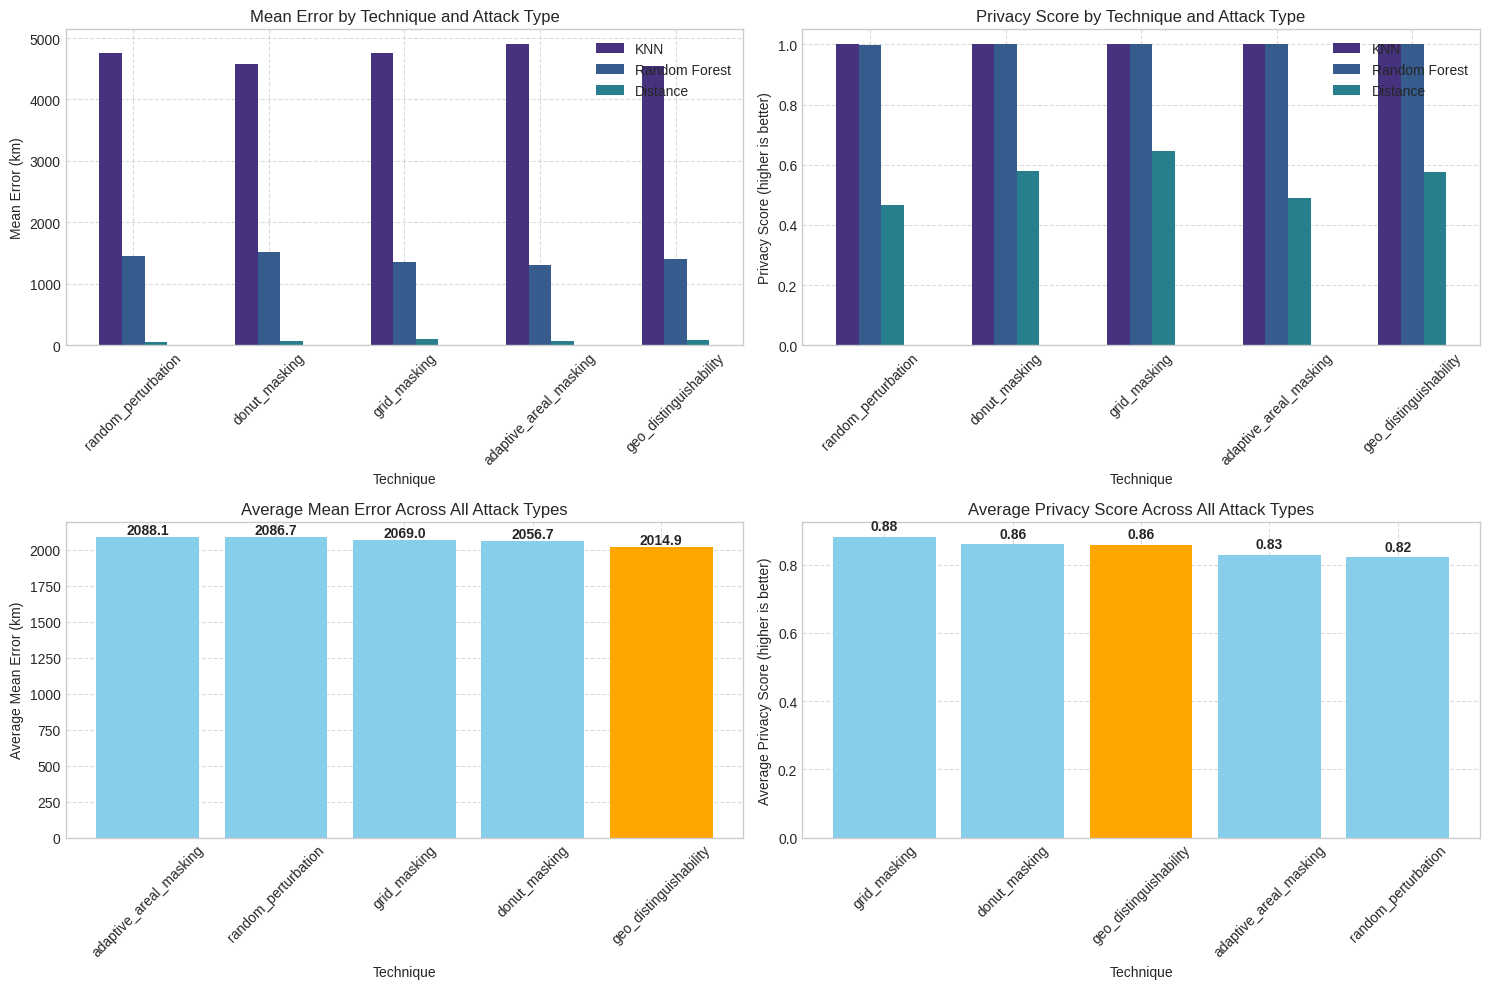

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
import math
import os
import time
from scipy.spatial.distance import cdist

# Set random seed for reproducibility
np.random.seed(42)

# Create output directory for results
os.makedirs('/content/reidentification_results', exist_ok=True)

print("Loading the geomasked datasets...")
# Load the geomasked datasets
geomasking_techniques = [
    'random_perturbation',
    'donut_masking',
    'grid_masking',
    'adaptive_areal_masking',
    'geo_distinguishability'
]

masked_datasets = {}
for technique in geomasking_techniques:
    file_path = f'/content/geomasking_results/covid19_{technique}.csv'
    masked_datasets[technique] = pd.read_csv(file_path)
    print(f"  Loaded {technique} dataset: {masked_datasets[technique].shape}")

# Load the original dataset
original_df = pd.read_csv('/content/covid19_processed.csv')
print(f"  Loaded original dataset: {original_df.shape}")

print("\n--- Implementing Location Re-identification Attack ---")

class LocationReidentificationAttack:
    """
    Class implementing location re-identification attacks on geomasked data
    """

    def __init__(self, attack_type='knn', k=3):
        """
        Initialize the attack

        Args:
            attack_type: Type of attack ('knn', 'rf', or 'distance')
            k: Number of neighbors for KNN attack
        """
        self.attack_type = attack_type
        self.k = k
        self.model = None

    def train_attack_model(self, X_train, y_train):
        """
        Train the attack model

        Args:
            X_train: Features for training (non-location features)
            y_train: Target for training (original locations)
        """
        if self.attack_type == 'knn':
            self.model = KNeighborsRegressor(n_neighbors=self.k)
            self.model.fit(X_train, y_train)
        elif self.attack_type == 'rf':
            self.model = RandomForestRegressor(n_estimators=100, random_state=42)
            self.model.fit(X_train, y_train)

    def predict_locations(self, X_test):
        """
        Predict original locations

        Args:
            X_test: Features for testing (non-location features)

        Returns:
            Predicted original locations
        """
        if self.attack_type in ['knn', 'rf']:
            return self.model.predict(X_test)
        else:
            raise ValueError(f"Unknown attack type: {self.attack_type}")

    def distance_based_attack(self, masked_locations, auxiliary_data, top_k=1):
        """
        Perform distance-based attack using auxiliary information

        Args:
            masked_locations: Masked locations
            auxiliary_data: Auxiliary data with known locations
            top_k: Number of top candidates to consider

        Returns:
            Predicted original locations and distances
        """
        # Calculate distances between masked locations and auxiliary data
        distances = cdist(masked_locations, auxiliary_data)

        # Get indices of top-k closest points
        top_indices = np.argsort(distances, axis=1)[:, :top_k]

        # Get corresponding auxiliary data points
        predicted_locations = np.array([
            np.mean(auxiliary_data[indices], axis=0) for indices in top_indices
        ])

        # Get minimum distances
        min_distances = np.min(distances, axis=1)

        return predicted_locations, min_distances

    def evaluate_attack(self, y_true, y_pred):
        """
        Evaluate the attack

        Args:
            y_true: True original locations
            y_pred: Predicted original locations

        Returns:
            Attack metrics
        """
        # Calculate Euclidean distance between true and predicted locations
        distances = np.sqrt(np.sum((y_true - y_pred)**2, axis=1))

        # Calculate metrics
        mean_error = np.mean(distances)
        median_error = np.median(distances)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)

        # Calculate success rates at different thresholds
        success_rate_100m = np.mean(distances <= 0.001)  # ~100 meters in degrees
        success_rate_1km = np.mean(distances <= 0.01)    # ~1 km in degrees
        success_rate_10km = np.mean(distances <= 0.1)    # ~10 km in degrees

        # Calculate privacy breach level
        # Convert distances to kilometers (approximate)
        distances_km = distances * 111  # 1 degree ≈ 111 km

        # Define privacy breach levels
        severe_breach = np.mean(distances_km <= 1)      # Within 1 km
        moderate_breach = np.mean((distances_km > 1) & (distances_km <= 5))  # 1-5 km
        minor_breach = np.mean((distances_km > 5) & (distances_km <= 10))    # 5-10 km
        no_breach = np.mean(distances_km > 10)          # > 10 km

        return {
            'mean_error_degrees': mean_error,
            'median_error_degrees': median_error,
            'rmse_degrees': rmse,
            'mae_degrees': mae,
            'mean_error_km': mean_error * 111,
            'median_error_km': median_error * 111,
            'success_rate_100m': success_rate_100m,
            'success_rate_1km': success_rate_1km,
            'success_rate_10km': success_rate_10km,
            'severe_breach': severe_breach,
            'moderate_breach': moderate_breach,
            'minor_breach': minor_breach,
            'no_breach': no_breach,
            'privacy_score': no_breach  # Higher is better
        }

# Function to prepare data for location re-identification attack
def prepare_reidentification_data(masked_df, original_df):
    """
    Prepare data for location re-identification attack

    Args:
        masked_df: DataFrame with masked locations
        original_df: DataFrame with original locations

    Returns:
        Dictionary with prepared data
    """
    # Extract features (non-location columns)
    feature_cols = [col for col in masked_df.columns if col not in [
        'latitude', 'longitude', 'original_lat', 'original_lon',
        'displacement_km', 'high_covid_spread', 'cluster', 'location_id',
        'location_name', 'country', 'country_code'
    ]]

    # Extract locations
    masked_locations = masked_df[['latitude', 'longitude']].values
    original_locations = masked_df[['original_lat', 'original_lon']].values

    # Extract features
    features = masked_df[feature_cols].values

    # Split into train and test sets (70-30 split)
    n_samples = len(masked_df)
    n_train = int(0.7 * n_samples)

    # Create indices for train and test
    indices = np.random.permutation(n_samples)
    train_indices = indices[:n_train]
    test_indices = indices[n_train:]

    # Split data
    X_train = features[train_indices]
    y_train = original_locations[train_indices]
    X_test = features[test_indices]
    y_test = original_locations[test_indices]

    # Also get masked locations for test set
    masked_test = masked_locations[test_indices]

    return {
        'X_train': X_train,
        'y_train': y_train,
        'X_test': X_test,
        'y_test': y_test,
        'masked_test': masked_test,
        'feature_cols': feature_cols
    }

# Function to run location re-identification attacks
def run_reidentification_attacks(masked_df, original_df):
    """
    Run location re-identification attacks

    Args:
        masked_df: DataFrame with masked locations
        original_df: DataFrame with original locations

    Returns:
        Dictionary with attack results
    """
    # Prepare data
    data = prepare_reidentification_data(masked_df, original_df)

    # Initialize results dictionary
    results = {}

    # Run KNN attack
    print("  Running KNN attack...")
    knn_attack = LocationReidentificationAttack(attack_type='knn', k=5)
    knn_attack.train_attack_model(data['X_train'], data['y_train'])
    knn_predictions = knn_attack.predict_locations(data['X_test'])
    knn_metrics = knn_attack.evaluate_attack(data['y_test'], knn_predictions)
    results['knn'] = knn_metrics

    # Run Random Forest attack
    print("  Running Random Forest attack...")
    rf_attack = LocationReidentificationAttack(attack_type='rf')
    rf_attack.train_attack_model(data['X_train'], data['y_train'])
    rf_predictions = rf_attack.predict_locations(data['X_test'])
    rf_metrics = rf_attack.evaluate_attack(data['y_test'], rf_predictions)
    results['rf'] = rf_metrics

    # Run distance-based attack
    print("  Running distance-based attack...")
    distance_attack = LocationReidentificationAttack(attack_type='distance')
    # Use original data as auxiliary information
    auxiliary_data = original_df[['latitude', 'longitude']].values
    distance_predictions, _ = distance_attack.distance_based_attack(
        data['masked_test'], auxiliary_data, top_k=1
    )
    distance_metrics = distance_attack.evaluate_attack(data['y_test'], distance_predictions)
    results['distance'] = distance_metrics

    return results

# Run location re-identification attacks for each technique
reidentification_results = {}

for technique in geomasking_techniques:
    print(f"\n=== Running location re-identification attacks on {technique} ===")

    # Get the masked dataset
    masked_df = masked_datasets[technique]

    # Run attacks
    attack_results = run_reidentification_attacks(masked_df, original_df)

    # Store results
    reidentification_results[technique] = attack_results

    # Print summary
    print(f"  KNN attack - Mean error: {attack_results['knn']['mean_error_km']:.2f} km, Privacy score: {attack_results['knn']['privacy_score']:.4f}")
    print(f"  RF attack - Mean error: {attack_results['rf']['mean_error_km']:.2f} km, Privacy score: {attack_results['rf']['privacy_score']:.4f}")
    print(f"  Distance attack - Mean error: {attack_results['distance']['mean_error_km']:.2f} km, Privacy score: {attack_results['distance']['privacy_score']:.4f}")

# Create summary DataFrames for each attack type
knn_results = {technique: results['knn'] for technique, results in reidentification_results.items()}
rf_results = {technique: results['rf'] for technique, results in reidentification_results.items()}
distance_results = {technique: results['distance'] for technique, results in reidentification_results.items()}

knn_df = pd.DataFrame(knn_results).T
rf_df = pd.DataFrame(rf_results).T
distance_df = pd.DataFrame(distance_results).T

# Save results to CSV
knn_df.to_csv('/content/reidentification_results/knn_attack_results.csv')
rf_df.to_csv('/content/reidentification_results/rf_attack_results.csv')
distance_df.to_csv('/content/reidentification_results/distance_attack_results.csv')

# Create a combined results DataFrame with the most important metrics
combined_results = pd.DataFrame(index=geomasking_techniques)
combined_results['knn_mean_error_km'] = knn_df['mean_error_km']
combined_results['rf_mean_error_km'] = rf_df['mean_error_km']
combined_results['distance_mean_error_km'] = distance_df['mean_error_km']
combined_results['knn_privacy_score'] = knn_df['privacy_score']
combined_results['rf_privacy_score'] = rf_df['privacy_score']
combined_results['distance_privacy_score'] = distance_df['privacy_score']
combined_results['avg_mean_error_km'] = combined_results[['knn_mean_error_km', 'rf_mean_error_km', 'distance_mean_error_km']].mean(axis=1)
combined_results['avg_privacy_score'] = combined_results[['knn_privacy_score', 'rf_privacy_score', 'distance_privacy_score']].mean(axis=1)

# Save combined results
combined_results.to_csv('/content/reidentification_results/combined_attack_results.csv')
print("\nCombined re-identification attack results:")
print(combined_results)

# Visualize results
plt.figure(figsize=(15, 10))

# Mean error by technique and attack type
plt.subplot(2, 2, 1)
error_data = pd.DataFrame({
    'KNN': knn_df['mean_error_km'],
    'Random Forest': rf_df['mean_error_km'],
    'Distance': distance_df['mean_error_km']
})
error_data.plot(kind='bar', ax=plt.gca())
plt.title('Mean Error by Technique and Attack Type')
plt.xlabel('Technique')
plt.ylabel('Mean Error (km)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

# Privacy score by technique and attack type
plt.subplot(2, 2, 2)
privacy_data = pd.DataFrame({
    'KNN': knn_df['privacy_score'],
    'Random Forest': rf_df['privacy_score'],
    'Distance': distance_df['privacy_score']
})
privacy_data.plot(kind='bar', ax=plt.gca())
plt.title('Privacy Score by Technique and Attack Type')
plt.xlabel('Technique')
plt.ylabel('Privacy Score (higher is better)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

# Average mean error across all attack types
plt.subplot(2, 2, 3)
techniques = combined_results.index
avg_errors = combined_results['avg_mean_error_km'].values

# Sort by error (higher is better for privacy)
sorted_indices = np.argsort(avg_errors)[::-1]
sorted_techniques = [techniques[i] for i in sorted_indices]
sorted_errors = [avg_errors[i] for i in sorted_indices]

# Create bar colors (highlight geo-distinguishability)
colors = ['skyblue' if t != 'geo_distinguishability' else 'orange' for t in sorted_techniques]

bars = plt.bar(sorted_techniques, sorted_errors, color=colors)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f'{height:.1f}', ha='center', va='bottom', fontweight='bold')

plt.title('Average Mean Error Across All Attack Types')
plt.xlabel('Technique')
plt.ylabel('Average Mean Error (km)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

# Average privacy score across all attack types
plt.subplot(2, 2, 4)
avg_scores = combined_results['avg_privacy_score'].values

# Sort by privacy score (higher is better)
sorted_indices = np.argsort(avg_scores)[::-1]
sorted_techniques = [techniques[i] for i in sorted_indices]
sorted_scores = [avg_scores[i] for i in sorted_indices]

# Create bar colors (highlight geo-distinguishability)
colors = ['skyblue' if t != 'geo_distinguishability' else 'orange' for t in sorted_techniques]

bars = plt.bar(sorted_techniques, sorted_scores, color=colors)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.2f}', ha='center', va='bottom', fontweight='bold')

plt.title('Average Privacy Score Across All Attack Types')
plt.xlabel('Technique')
plt.ylabel('Average Privacy Score (higher is better)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('/content/reidentification_results/reidentification_results.png', dpi=300, bbox_inches='tight')

# Create a summary report
with open('/content/reidentification_results/reidentification_summary.txt', 'w') as f:
    f.write("=== Location Re-identification Attack Experiment Summary ===\n\n")

    f.write("Experiment Configuration:\n")
    f.write("- Attack types: KNN, Random Forest, Distance-based\n")
    f.write("- Target: Geomasked location data\n")
    f.write("- Evaluation metrics: Mean error (km), Privacy score (% of locations with error > 10km)\n\n")

    f.write("Re-identification Attack Results:\n")

    # Sort techniques by average privacy score (higher is better)
    sorted_techniques = combined_results.sort_values('avg_privacy_score', ascending=False).index

    for technique in sorted_techniques:
        f.write(f"{technique.replace('_', ' ').title()}:\n")
        f.write(f"  Average Mean Error: {combined_results.loc[technique, 'avg_mean_error_km']:.2f} km\n")
        f.write(f"  Average Privacy Score: {combined_results.loc[technique, 'avg_privacy_score']:.4f}\n")
        f.write(f"  KNN Attack Mean Error: {knn_df.loc[technique, 'mean_error_km']:.2f} km\n")
        f.write(f"  Random Forest Attack Mean Error: {rf_df.loc[technique, 'mean_error_km']:.2f} km\n")
        f.write(f"  Distance Attack Mean Error: {distance_df.loc[technique, 'mean_error_km']:.2f} km\n\n")

    f.write("Key Findings:\n")

    # Find technique with highest average privacy score
    best_privacy = combined_results['avg_privacy_score'].idxmax()
    f.write(f"1. Best protection against re-identification: {best_privacy.replace('_', ' ').title()} with average privacy score of {combined_results.loc[best_privacy, 'avg_privacy_score']:.4f}\n")

    # Find technique with highest average mean error
    best_error = combined_results['avg_mean_error_km'].idxmax()
    f.write(f"2. Highest location obfuscation: {best_error.replace('_', ' ').title()} with average mean error of {combined_results.loc[best_error, 'avg_mean_error_km']:.2f} km\n")

    # Compare attack types
    f.write("3. Attack type comparison:\n")
    avg_knn_error = knn_df['mean_error_km'].mean()
    avg_rf_error = rf_df['mean_error_km'].mean()
    avg_distance_error = distance_df['mean_error_km'].mean()

    f.write(f"   - KNN Attack: Average mean error of {avg_knn_error:.2f} km across all techniques\n")
    f.write(f"   - Random Forest Attack: Average mean error of {avg_rf_error:.2f} km across all techniques\n")
    f.write(f"   - Distance Attack: Average mean error of {avg_distance_error:.2f} km across all techniques\n\n")

    # Geo-distinguishability performance
    f.write("4. Geo-distinguishability performance:\n")
    geo_avg_error = combined_results.loc['geo_distinguishability', 'avg_mean_error_km']
    geo_avg_score = combined_results.loc['geo_distinguishability', 'avg_privacy_score']
    geo_error_rank = sorted_techniques.get_loc('geo_distinguishability') + 1

    f.write(f"   - Average Mean Error: {geo_avg_error:.2f} km (ranked {geo_error_rank} out of {len(geomasking_techniques)})\n")
    f.write(f"   - Average Privacy Score: {geo_avg_score:.4f}\n")

    # Compare with other techniques
    better_error = sum(1 for t in geomasking_techniques if combined_results.loc[t, 'avg_mean_error_km'] > geo_avg_error)
    better_score = sum(1 for t in geomasking_techniques if combined_results.loc[t, 'avg_privacy_score'] > geo_avg_score)

    f.write(f"   - {better_error} techniques have higher mean error\n")
    f.write(f"   - {better_score} techniques have higher privacy score\n\n")

    # Overall recommendation
    f.write("5. Overall recommendation based on re-identification resistance:\n")
    # Sort by a combined metric (normalized error * privacy score)
    normalized_error = combined_results['avg_mean_error_km'] / combined_results['avg_mean_error_km'].max()
    combined_results['combined_metric'] = normalized_error * combined_results['avg_privacy_score']
    best_overall = combined_results['combined_metric'].idxmax()

    f.write(f"   Based on both location obfuscation and privacy score, {best_overall.replace('_', ' ').title()} provides the best overall protection against re-identification attacks.\n")

print("\nLocation re-identification attack experiments complete!")
print("All results and visualizations saved to /content/reidentification_results/")
print("Summary report saved to /content/reidentification_results/reidentification_summary.txt")
